> **ENTIRE SETUP**

In [1]:
# ============================================================
# CELL 1 — SETUP (run once per session)
# ============================================================
import sys
sys.path.insert(0, "/kaggle/input/datasets/yasufuminakama/pytorch-image-models/pytorch-image-models-master")

import torch, torch.nn as nn, torch.nn.functional as F
import timm, numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
import os

print("timm version:", timm.__version__)

# ---- paths (verify which BASE exists) ----
for cand in ["/kaggle/input/seti-breakthrough-listen",
             "/kaggle/input/competitions/seti-breakthrough-listen"]:
    if os.path.exists(cand):
        BASE = cand
        break
print("BASE:", BASE)

WEIGHTS = "/kaggle/input/datasets/omerimran1/frozen-detector-v1/efficientnet_b0_fold0_best_score.pth"
print("weights exist:", os.path.exists(WEIGHTS))

# ---- locked constants (never change these) ----
THRESHOLD   = 0.1309    # 1% FPR operating point
BASE_RECALL = 0.5525    # baseline recall at that threshold
CAL_AMP     = 0.5       # calibrated in-distribution amplitude (Session 7)

class CFG:
    model_name  = 'efficientnet_b0'
    input_size  = 512
    output_size = 256
    target_size = 1
    mode        = 'spatial_3'

# ---- locked constants (never change these) ----
THRESHOLD   = 0.1309    # 1% FPR operating point
BASE_RECALL = 0.5525    # baseline recall at that threshold
CAL_AMP     = 0.5       # calibrated in-distribution amplitude (Session 7)
LAYER       = 'cnn.blocks.4.0.conv_pwl'   # Grad-CAM target (S12: 16x16, in-band ratio 2.21)

print("Cell 1 done.")

timm version: 0.4.13
BASE: /kaggle/input/competitions/seti-breakthrough-listen
weights exist: True
Cell 1 done.


**MODEL**

In [2]:
# ============================================================
# CELL 2 — MODEL (architecture shell + frozen weights)
# ============================================================
class CustomModel(nn.Module):
    def __init__(self, cfg, pretrained=False):
        super().__init__()
        self.cfg = cfg
        self.n = 16
        self.slope = .1
        self.r = 1

        if self.cfg.mode in ['spatial_3', 'spatial_6']:
            self.cnn = timm.create_model(self.cfg.model_name, pretrained=pretrained, in_chans=1)
        elif self.cfg.mode == 'channel_3':
            self.cnn = timm.create_model(self.cfg.model_name, pretrained=pretrained, in_chans=3)
        elif self.cfg.mode == 'channel_6':
            self.cnn = timm.create_model(self.cfg.model_name, pretrained=pretrained, in_chans=6)

        if hasattr(self.cnn, "fc"):
            nb_ft = self.cnn.fc.in_features; self.cnn.fc = nn.Identity()
        elif hasattr(self.cnn, "_fc"):
            nb_ft = self.cnn._fc.in_features; self.cnn._fc = nn.Identity()
        elif hasattr(self.cnn, "classifier"):
            nb_ft = self.cnn.classifier.in_features; self.cnn.classifier = nn.Identity()
        elif hasattr(self.cnn, "last_linear"):
            nb_ft = self.cnn.last_linear.in_features; self.cnn.last_linear = nn.Identity()
        elif hasattr(self.cnn, "head"):
            nb_ft = self.cnn.head.in_features; self.cnn.head = nn.Identity()

        self.block1 = nn.Sequential(
                nn.Conv2d(1, self.n, kernel_size=(7,7), stride=(1,1), padding=(1,1), bias=False),
                nn.LeakyReLU(negative_slope=self.slope),
                nn.Conv2d(self.n, self.n, kernel_size=(1,1), stride=(1,1), padding=(1,1), bias=False),
                nn.LeakyReLU(negative_slope=self.slope),
                nn.BatchNorm2d(self.n))
        self.block2 = nn.Sequential(
                nn.Conv2d(self.n, self.n, kernel_size=(3,3), stride=(1,1), padding=(1,1), bias=False),
                nn.BatchNorm2d(self.n),
                nn.LeakyReLU(negative_slope=self.slope),
                nn.Conv2d(self.n, self.n, kernel_size=(3,3), stride=(1,1), padding=(1,1), bias=False),
                nn.BatchNorm2d(self.n))
        self.block3 = nn.Sequential(
                nn.Conv2d(self.n, self.n, kernel_size=(3,3), stride=(1,1), padding=(1,1), bias=False),
                nn.BatchNorm2d(self.n))
        self.block4 = nn.Sequential(
                nn.Conv2d(self.n, 1, kernel_size=(7,7), stride=(1,1), padding=(3,3), bias=False))
        self.fc = nn.Linear(nb_ft, self.cfg.target_size)

    def forward(self, x):
        res1 = F.interpolate(x, size=(self.cfg.output_size, self.cfg.output_size), mode='bilinear')
        x = self.block1(x)
        res2 = F.interpolate(x, size=(self.cfg.output_size, self.cfg.output_size), mode='bilinear')
        x = self.block2(res2); x += res2
        if self.r > 1:
            for _ in range(self.r):
                res2 = x; x = self.block2(x); x += res2
        x = self.block3(x); x += res2
        x = self.block4(x); x += res1
        x = self.cnn(x)
        x = self.fc(x)
        return x

# ---- load frozen weights ----
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = CustomModel(CFG, pretrained=False)

ckpt = torch.load(WEIGHTS, map_location=device, weights_only=False)
missing, unexpected = model.load_state_dict(ckpt['model'], strict=False)

model.to(device).eval()

print("Frozen model loaded.")
print("missing keys   :", len(missing))
print("unexpected keys:", len(unexpected))
if missing:    print("  e.g. missing:", missing[:5])
if unexpected: print("  e.g. unexpected:", unexpected[:5])

Frozen model loaded.
missing keys   : 0
unexpected keys: 0


**RECIPE + SCORING**

In [3]:
def preprocess(panels):
    """EXACT validation recipe. Do not deviate."""
    x = panels.astype(np.float32)                          # (3,273,256)
    x = np.vstack(x).transpose((1, 0))                     # -> (256,819)
    x = cv2.resize(x, (CFG.input_size, CFG.input_size))    # -> (512,512)
    return torch.from_numpy(x)[None, None, :, :].float()

@torch.no_grad()
def score(panels):
    return torch.sigmoid(model(preprocess(panels).to(device))).item()

def wilson(k, n, z=1.96):
    if n == 0: return (0, 0)
    p = k/n; d = 1 + z**2/n
    c = (p + z**2/(2*n))/d
    h = z*np.sqrt(p*(1-p)/n + z**2/(4*n**2))/d
    return (max(0, c-h), min(1, c+h))

**INJECTOR + SAMPLE LOADER**

In [4]:
def inject_needle(panel, amplitude=CAL_AMP, drift=3.0, width=1.2, freq_pos=None, seed=0):
    """Narrowband drifting needle, normalized (noise-std) units."""
    panel = panel.copy().astype(np.float32)
    n_time, n_freq = panel.shape
    rng = np.random.default_rng(seed)
    if freq_pos is None:
        freq_pos = rng.uniform(n_freq*0.3, n_freq*0.7)
    freq_axis = np.arange(n_freq)
    for t in range(n_time):
        center = freq_pos + drift * (t / n_time)
        panel[t] += amplitude * np.exp(-0.5*((freq_axis - center)/width)**2)
    return panel

labels  = pd.read_csv(f"{BASE}/train_labels.csv")
neg_ids = labels[labels['target']==0]['id'].values

def load_sample(fid, on_only=True):
    img = np.load(f"{BASE}/train/{fid[0]}/{fid}.npy").astype(np.float32)
    return img[::2].copy() if on_only else img.copy()

def load_cache(n=100, seed=0, on_only=True):
    rng = np.random.default_rng(seed)
    ids = rng.choice(neg_ids, n, replace=False)
    return [load_sample(f, on_only) for f in ids]

print("Setup complete.")

Setup complete.


In [5]:
# ============================================================
# CELL 5 — DIRECTION 2 GENERATORS (RFI mimicry)
# ============================================================

def _line(panel, center_fn, amplitude, width=1.2, time_mask=None):
    """Core primitive: draw a gaussian line whose freq-center varies with time."""
    out = panel.copy().astype(np.float32)
    n_time, n_freq = out.shape
    faxis = np.arange(n_freq)
    for t in range(n_time):
        if time_mask is not None and not time_mask[t]:
            continue
        c = center_fn(t, n_time)
        out[t] += amplitude * np.exp(-0.5*((faxis - c)/width)**2)
    return out


def d2_zero_drift(panel, amplitude, freq_pos, width=1.2, **kw):
    """D2-1: perfectly vertical carrier. drift = 0 Hz/s -> canonical RFI."""
    return _line(panel, lambda t, n: freq_pos, amplitude, width)


def d2_comb(panel, amplitude, freq_pos, width=1.2, spacing=18, n_teeth=4, drift=0.0, **kw):
    """D2-2: harmonic comb — several parallel tones, evenly spaced."""
    out = panel.copy().astype(np.float32)
    for k in range(n_teeth):
        fp = freq_pos + k*spacing
        if fp < panel.shape[1]:
            out = _line(out, lambda t, n, f=fp: f + drift*(t/n), amplitude, width)
    return out


def d2_intermittent(panel, amplitude, freq_pos, width=1.2, drift=0.0,
                    duty=0.4, period=40, **kw):
    """D2-3: duty-cycled carrier — blinks on/off in time."""
    n_time = panel.shape[0]
    mask = (np.arange(n_time) % period) < (period*duty)
    return _line(panel, lambda t, n: freq_pos + drift*(t/n), amplitude, width, mask)


def d2_broadband_burst(panel, amplitude, freq_pos=None, width=1.2,
                       t_center=None, t_width=3.0, seed=0, **kw):
    """D2-4: impulsive wideband burst — short in time, wide in frequency."""
    out = panel.copy().astype(np.float32)
    n_time, n_freq = out.shape
    rng = np.random.default_rng(seed)
    if t_center is None:
        t_center = rng.uniform(n_time*0.2, n_time*0.8)
    taxis = np.arange(n_time)
    envelope = amplitude * np.exp(-0.5*((taxis - t_center)/t_width)**2)
    for t in range(n_time):
        if envelope[t] > 1e-4:
            out[t] += envelope[t]          # spans ALL frequencies
    return out


def d2_high_drift(panel, amplitude, freq_pos, width=1.2, drift=45.0, **kw):
    """D2-5: satellite-like fast drifter. PASSES the drift test, still RFI."""
    return _line(panel, lambda t, n: freq_pos + drift*(t/n), amplitude, width)


D2_FAMILIES = {
    'D2-1_zero_drift'      : d2_zero_drift,
    'D2-2_comb'            : d2_comb,
    'D2-3_intermittent'    : d2_intermittent,
    'D2-4_broadband_burst' : d2_broadband_burst,
    'D2-5_high_drift'      : d2_high_drift,
}
print("Direction 2 generators defined:", list(D2_FAMILIES))

Direction 2 generators defined: ['D2-1_zero_drift', 'D2-2_comb', 'D2-3_intermittent', 'D2-4_broadband_burst', 'D2-5_high_drift']


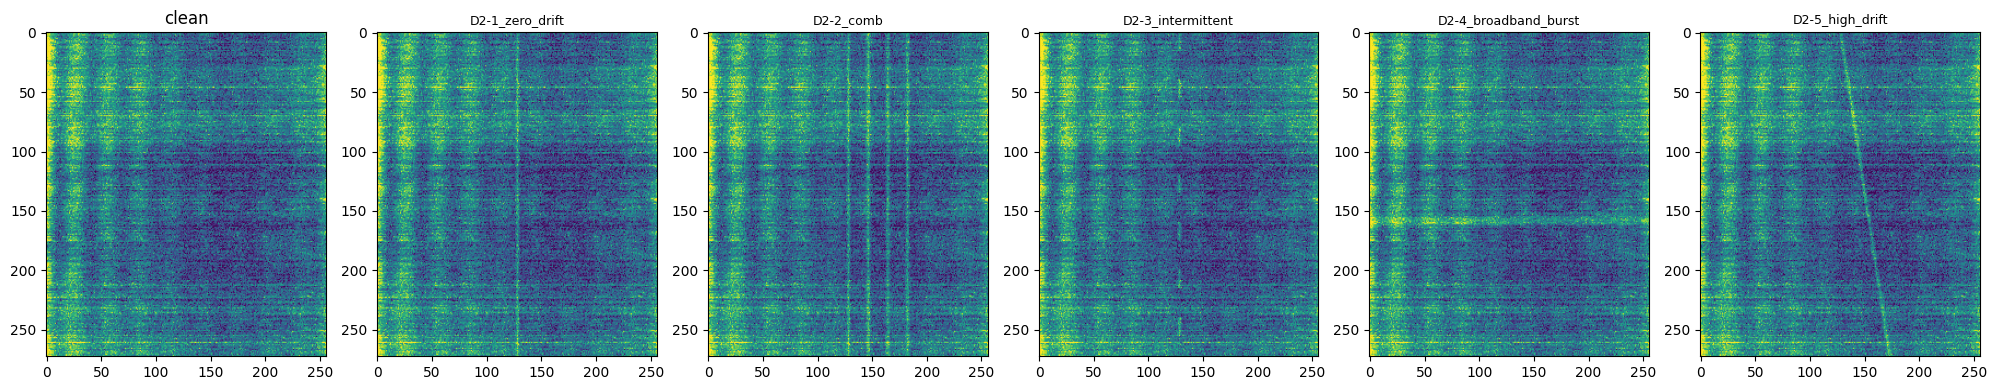

In [6]:
p = load_sample(neg_ids[0])[0]          # one real ON panel
fig, ax = plt.subplots(1, 6, figsize=(20, 4))
ax[0].imshow(p, aspect='auto', vmin=-2, vmax=3); ax[0].set_title("clean")
for i, (name, fn) in enumerate(D2_FAMILIES.items()):
    ax[i+1].imshow(fn(p, amplitude=CAL_AMP*3, freq_pos=128, seed=0),
                   aspect='auto', vmin=-2, vmax=3)
    ax[i+1].set_title(name, fontsize=9)
plt.tight_layout(); plt.show()

In [7]:
p = load_sample(neg_ids[0])[0]
a = d2_zero_drift(p, amplitude=CAL_AMP*3, freq_pos=128)
b = d2_intermittent(p, amplitude=CAL_AMP*3, freq_pos=128)
print("zero_drift rows:", int((a-p).max(axis=1).round(3).astype(bool).sum()))
print("intermittent rows:", int((b-p).max(axis=1).round(3).astype(bool).sum()))

zero_drift rows: 273
intermittent rows: 112


In [8]:
# ============================================================
# CELL 8 — DIRECTION 1 GENERATORS (unseen alien morphologies)
# Ordered by distance from the training distribution
# ============================================================

def d1_extreme_drift(panel, amplitude, freq_pos, width=1.2, drift=60.0, **kw):
    """D1-1 (nearest): same shape as training, but leaning far harder."""
    return _line(panel, lambda t, n: freq_pos + drift*(t/n), amplitude, width)


def d1_quadratic(panel, amplitude, freq_pos, width=1.2, curve=60.0, drift=0.0, **kw):
    """D1-2 (near): accelerating source — same endpoint as D1-1, curved path."""
    return _line(panel,
                 lambda t, n: freq_pos + drift*(t/n) + curve*(t/n)**2,
                 amplitude, width)


def d1_s_shaped(panel, amplitude, freq_pos, width=1.2, swing=25.0, cycles=1.0, **kw):
    """D1-3 (mid): the Watercooled shape. Orbital wobble — bends one way then back."""
    return _line(panel,
                 lambda t, n: freq_pos + swing*np.sin(2*np.pi*cycles*(t/n)),
                 amplitude, width)


def d1_pulsed(panel, amplitude, freq_pos, width=1.2, drift=5.0,
              duty=0.35, period=55, **kw):
    """D1-4 (far): a beacon that switches on and off — dashes, not a line."""
    n_time = panel.shape[0]
    mask = (np.arange(n_time) % period) < (period*duty)
    return _line(panel, lambda t, n: freq_pos + drift*(t/n), amplitude, width, mask)


def d1_dispersed_burst(panel, amplitude, freq_pos=None, width=1.2,
                       t0=30.0, sweep=180.0, thickness=6.0, seed=0, **kw):
    """D1-5 (farthest): broadband pulse smeared across frequency — not narrowband at all."""
    out = panel.copy().astype(np.float32)
    n_time, n_freq = out.shape
    faxis = np.arange(n_freq)
    for t in range(n_time):
        # each frequency arrives at a slightly different time (dispersion)
        arrival = t0 + sweep*(faxis/n_freq)**2
        out[t] += amplitude * np.exp(-0.5*((t - arrival)/thickness)**2)
    return out


D1_FAMILIES = {
    'D1-1_extreme_drift'    : d1_extreme_drift,
    'D1-2_quadratic'        : d1_quadratic,
    'D1-3_s_shaped'         : d1_s_shaped,
    'D1-4_pulsed'           : d1_pulsed,
    'D1-5_dispersed_burst'  : d1_dispersed_burst,
}
print("Direction 1 generators defined:", list(D1_FAMILIES))

Direction 1 generators defined: ['D1-1_extreme_drift', 'D1-2_quadratic', 'D1-3_s_shaped', 'D1-4_pulsed', 'D1-5_dispersed_burst']


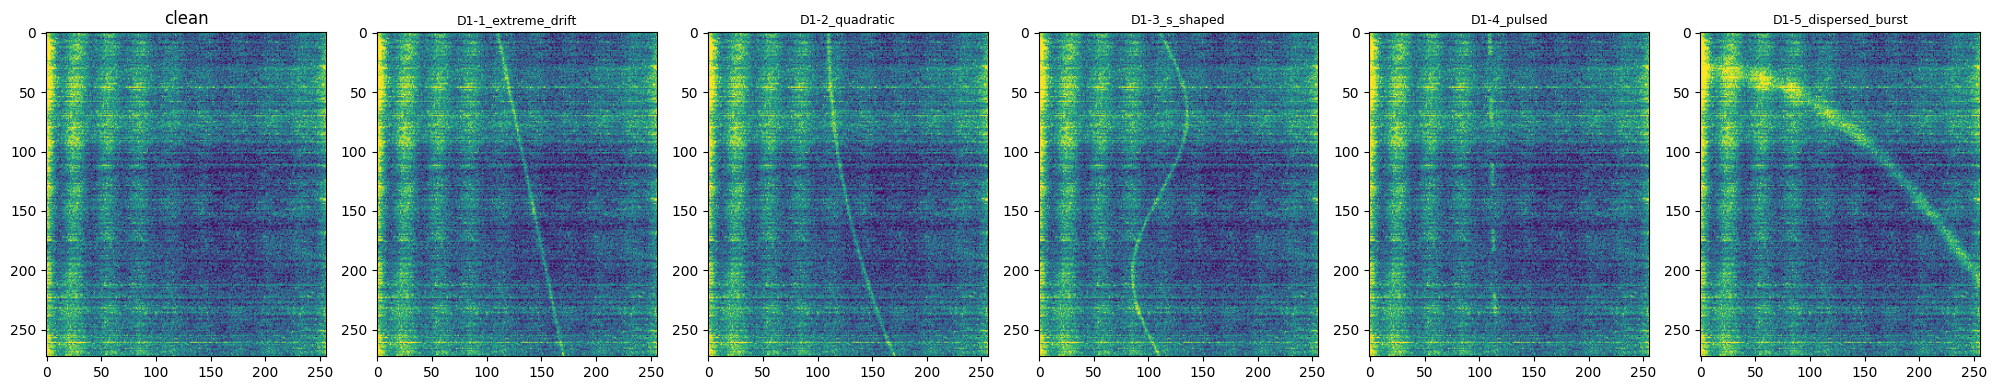

In [9]:
p = load_sample(neg_ids[0])[0]
fig, ax = plt.subplots(1, 6, figsize=(20, 4))
ax[0].imshow(p, aspect='auto', vmin=-2, vmax=3); ax[0].set_title("clean")
for i, (name, fn) in enumerate(D1_FAMILIES.items()):
    ax[i+1].imshow(fn(p, amplitude=CAL_AMP*3, freq_pos=110, seed=0),
                   aspect='auto', vmin=-2, vmax=3)
    ax[i+1].set_title(name, fontsize=9)
plt.tight_layout(); plt.show()

In [10]:
p = load_sample(neg_ids[0])[0]
b = d1_pulsed(p, amplitude=CAL_AMP*3, freq_pos=110)
print("rows with signal:", int((b-p).max(axis=1).round(3).astype(bool).sum()), "— expect ~95")

rows with signal: 100 — expect ~95


In [11]:
def d1_dispersed_burst(panel, amplitude, freq_pos=None, width=1.2,
                       t0=None, sweep=None, thickness=6.0, seed=0, **kw):
    """D1-5 (farthest): broadband pulse smeared across frequency. Randomised per sample."""
    out = panel.copy().astype(np.float32)
    n_time, n_freq = out.shape
    rng = np.random.default_rng(seed)
    if t0    is None: t0    = rng.uniform(10, 80)
    if sweep is None: sweep = rng.uniform(120, 240)
    faxis = np.arange(n_freq)
    for t in range(n_time):
        arrival = t0 + sweep*(faxis/n_freq)**2
        out[t] += amplitude * np.exp(-0.5*((t - arrival)/thickness)**2)
    return out

D1_FAMILIES['D1-5_dispersed_burst'] = d1_dispersed_burst

# verify it now differs between samples
a = d1_dispersed_burst(p, amplitude=CAL_AMP*3, seed=0)
b2 = d1_dispersed_burst(p, amplitude=CAL_AMP*3, seed=7)
print("bursts differ between seeds:", not np.allclose(a, b2))

bursts differ between seeds: True


In [12]:
# ============================================================
# CELL 9 — LOAD the frozen manifest (do NOT regenerate; hash() varies per session)
# ============================================================
import glob
MANIFEST_PATH = glob.glob("/kaggle/input/**/injection_manifest.csv", recursive=True)[0]
man = pd.read_csv(MANIFEST_PATH)

print("manifest:", MANIFEST_PATH)
print(man.shape)                        # (15000, 9)
print(man.family.nunique(), "families,", man.source_id.nunique(), "sources")
print(sorted(man.amplitude.unique()))

manifest: /kaggle/input/datasets/omerimran1/seti-injection-manifest-v1/injection_manifest.csv
(15000, 9)
10 families, 300 sources
[np.float64(0.25), np.float64(0.5), np.float64(1.0), np.float64(2.0), np.float64(4.0)]


In [13]:
# ============================================================
# CELL 10 — REGENERATE a sample from its manifest row
# ============================================================
FAM_FN = {**D2_FAMILIES, **D1_FAMILIES}

def regenerate(row, base=None):
    if base is None:
        base = load_sample(row['source_id'], on_only=False)
    out = base.copy()
    fn  = FAM_FN[row['family']]
    for j in [int(x) for x in row['panels'].split('|')]:
        out[j] = fn(base[j], amplitude=row['amplitude'],
                    freq_pos=row['freq_pos'], seed=int(row['seed']))
    return out

# determinism check — regenerate the same row twice, must be identical
r = man.iloc[0]
a, b = regenerate(r), regenerate(r)
print("row:", r['sample_id'])
print("deterministic:", np.array_equal(a, b))
print("shape:", a.shape)

row: D2-1_zero_drift_amp0.25_0000
deterministic: True
shape: (6, 273, 256)


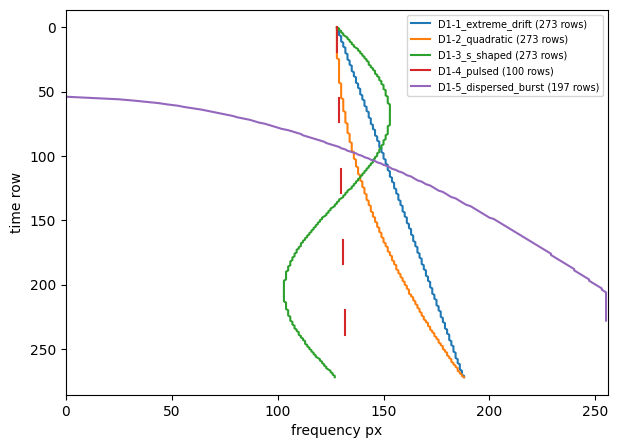

In [14]:
p = load_sample(neg_ids[0])[0]
fig, ax = plt.subplots(figsize=(7,5))

for name, fn in D1_FAMILIES.items():
    d = fn(p, amplitude=CAL_AMP*3, freq_pos=128, seed=0) - p   # signal only
    rows = d.max(axis=1) > 1e-3                                # rows containing signal
    traj = np.where(rows, d.argmax(axis=1), np.nan)
    ax.plot(traj, np.arange(len(traj)), label=f"{name} ({rows.sum()} rows)")

ax.invert_yaxis(); ax.set_xlim(0, 256)
ax.set_xlabel("frequency px"); ax.set_ylabel("time row")
ax.legend(fontsize=7); plt.show()

In [15]:
import time
src_ids = man.source_id.unique()
t0 = time.time()
SRC = {s: load_sample(s, on_only=False) for s in src_ids}
print(f"cached {len(SRC)} in {time.time()-t0:.0f}s, "
      f"{sum(a.nbytes for a in SRC.values())/1e9:.2f} GB")

cached 300 in 7s, 0.50 GB


In [16]:
@torch.no_grad()
def score_batch(arrs):
    x = torch.from_numpy(np.stack(arrs)[:, None]).float().to(device)
    return torch.sigmoid(model(x)).squeeze(1).cpu().numpy()

def prep_np(sample6):
    x = sample6[::2].astype(np.float32)
    x = np.vstack(x).transpose((1, 0))
    return cv2.resize(x, (CFG.input_size, CFG.input_size))

## PHASE 3 — SCORING

In [17]:
# Purpose: score the full 15,000-row manifest. Skips entirely if a valid scores
# file already exists (copied from a saved dataset), so Run All costs seconds
# instead of 6.5 minutes.
# NOTE: glob ONLY under /kaggle/input/datasets — a recursive glob over all of
# /kaggle/input walks the 156 GB competition tree and can hang for hours (S17).
import os, glob, shutil, time

BATCH = 32
OUT   = "/kaggle/working/phase3_scores.csv"

PRIOR = glob.glob("/kaggle/input/datasets/**/phase3_scores.csv", recursive=True)
if PRIOR and not os.path.exists(OUT):
    shutil.copy(PRIOR[0], OUT)
    print("copied saved scores from", PRIOR[0])

SKIP = os.path.exists(OUT) and len(pd.read_csv(OUT)) == 15000

if SKIP:
    print("phase3_scores.csv already complete (15000 rows) — skipping re-scoring")
else:
    records = man.to_dict("records")
    buf, buf_ids, ids, scores = [], [], [], []
    model.eval(); t0 = time.time()
    for i, row in enumerate(records):
        buf.append(prep_np(regenerate(row, base=SRC[row['source_id']])))
        buf_ids.append(row['sample_id'])
        if len(buf) == BATCH:
            scores.extend(score_batch(buf)); ids.extend(buf_ids); buf, buf_ids = [], []
        if (i+1) % 3000 == 0:
            pd.DataFrame({"sample_id": ids, "score": scores}).to_csv(OUT, index=False)
            print(f"{i+1}/{len(records)}  {time.time()-t0:.0f}s")
    if buf:
        scores.extend(score_batch(buf)); ids.extend(buf_ids)
    pd.DataFrame({"sample_id": ids, "score": scores}).to_csv(OUT, index=False)
    print("done", f"{time.time()-t0:.0f}s", len(ids))

copied saved scores from /kaggle/input/datasets/omerimran1/seti-phase3-scores-v1/phase3_scores.csv
phase3_scores.csv already complete (15000 rows) — skipping re-scoring


In [18]:
# Purpose: clean control arm — same 300 backgrounds, no injection. Every FPR is
# judged against this. Skips if already computed.
# NOTE: glob ONLY under /kaggle/input/datasets (full-tree glob hangs — S17).
CTRL  = "/kaggle/working/clean_control_scores.csv"
PRIOR = glob.glob("/kaggle/input/datasets/**/clean_control_scores.csv", recursive=True)
if PRIOR and not os.path.exists(CTRL):
    shutil.copy(PRIOR[0], CTRL)
    print("copied saved control scores from", PRIOR[0])

if os.path.exists(CTRL) and len(pd.read_csv(CTRL)) == 300:
    cs = pd.read_csv(CTRL).score.values
    print("clean control already computed — skipping")
else:
    cb = [prep_np(SRC[s]) for s in src_ids]
    cs = np.concatenate([score_batch(cb[i:i+BATCH]) for i in range(0, len(cb), BATCH)])
    pd.DataFrame({"source_id": src_ids, "score": cs}).to_csv(CTRL, index=False)

lo, hi = wilson((cs > THRESHOLD).sum(), len(cs))
print(f"clean FPR: {(cs>THRESHOLD).mean():.3f}  [{lo:.3f}, {hi:.3f}]   (expect 0.013)")

copied saved control scores from /kaggle/input/datasets/omerimran1/seti-phase3-scores-v1/clean_control_scores.csv
clean control already computed — skipping
clean FPR: 0.013  [0.005, 0.034]   (expect 0.013)


In [19]:
sc = pd.read_csv("/kaggle/working/phase3_scores.csv")
df = man.merge(sc, on="sample_id")
assert len(df) == 15000
df["hit"] = df.score > THRESHOLD

g = df.groupby(["direction","family","amplitude"]).hit.agg(["sum","count"]).reset_index()
g["rate"] = g["sum"]/g["count"]
g[["lo","hi"]] = pd.DataFrame([wilson(k,n) for k,n in zip(g["sum"],g["count"])], index=g.index)
g.to_csv("/kaggle/working/phase3_summary.csv", index=False)

for d, lbl in [(2,"FALSE-POSITIVE RATE"), (1,"RECALL")]:
    print(f"\n===== DIRECTION {d} — {lbl} =====")
    print(g[g.direction==d].pivot(index="family", columns="amplitude", values="rate").round(3))


===== DIRECTION 2 — FALSE-POSITIVE RATE =====
amplitude              0.25   0.50   1.00   2.00   4.00
family                                                 
D2-1_zero_drift       0.013  0.017  0.010  0.013  0.010
D2-2_comb             0.013  0.017  0.003  0.007  0.010
D2-3_intermittent     0.010  0.010  0.010  0.007  0.013
D2-4_broadband_burst  0.013  0.013  0.013  0.013  0.010
D2-5_high_drift       0.460  0.627  0.307  0.033  0.020

===== DIRECTION 1 — RECALL =====
amplitude              0.25   0.50   1.00   2.00   4.00
family                                                 
D1-1_extreme_drift    0.183  0.410  0.273  0.077  0.020
D1-2_quadratic        0.453  0.533  0.340  0.127  0.017
D1-3_s_shaped         0.253  0.570  0.750  0.880  0.900
D1-4_pulsed           0.023  0.017  0.017  0.003  0.010
D1-5_dispersed_burst  0.013  0.017  0.010  0.010  0.010


In [20]:
merged = df.merge(pd.read_csv("/kaggle/working/clean_control_scores.csv")
                    .rename(columns={"score":"clean_score"}), on="source_id")
for fam in ["D1-4_pulsed","D1-5_dispersed_burst"]:
    s = merged[(merged.family==fam) & (merged.amplitude==4.0)]
    print(f"{fam:24} injected {s.score.mean():.4f}   clean {s.clean_score.mean():.4f}   "
          f"identical: {np.allclose(s.score, s.clean_score)}")

D1-4_pulsed              injected 0.0473   clean 0.0478   identical: False
D1-5_dispersed_burst     injected 0.0458   clean 0.0478   identical: False


In [21]:
from scipy.stats import wilcoxon
clean  = pd.read_csv("/kaggle/working/clean_control_scores.csv").rename(columns={"score":"clean_score"})
merged = df.merge(clean, on="source_id")

for fam in ["D1-2_quadratic","D1-4_pulsed","D1-5_dispersed_burst"]:
    for amp in [0.5, 4.0]:
        s = merged[(merged.family==fam) & (merged.amplitude==amp)]
        d = s.score.values - s.clean_score.values
        stat, p = wilcoxon(d)
        print(f"{fam:22} amp {amp:<5} median Δ {np.median(d):+.5f}  p={p:.2e}  n={len(d)}")

D1-2_quadratic         amp 0.5   median Δ +0.09961  p=1.97e-48  n=300
D1-2_quadratic         amp 4.0   median Δ +0.02835  p=2.52e-44  n=300
D1-4_pulsed            amp 0.5   median Δ +0.00259  p=9.20e-25  n=300
D1-4_pulsed            amp 4.0   median Δ +0.00041  p=1.65e-01  n=300
D1-5_dispersed_burst   amp 0.5   median Δ -0.00011  p=4.24e-03  n=300
D1-5_dispersed_burst   amp 4.0   median Δ -0.00133  p=2.85e-11  n=300


## PHASE 3 — MONEY PLOTS

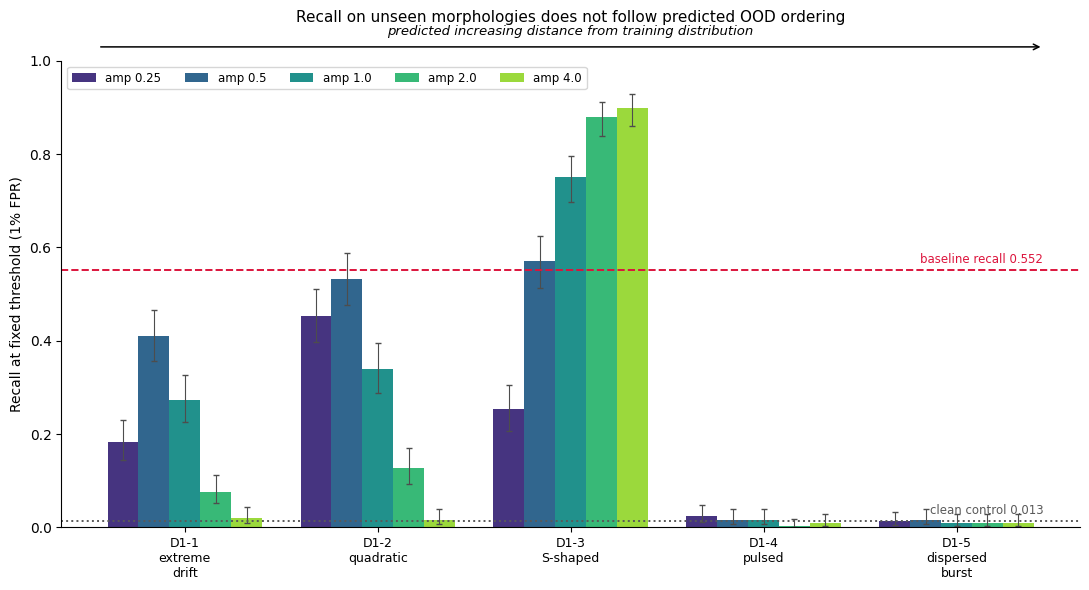

In [22]:
import matplotlib.pyplot as plt

ORDER = ['D1-1_extreme_drift','D1-2_quadratic','D1-3_s_shaped',
         'D1-4_pulsed','D1-5_dispersed_burst']
LABEL = ['D1-1\nextreme\ndrift','D1-2\nquadratic','D1-3\nS-shaped',
         'D1-4\npulsed','D1-5\ndispersed\nburst']
AMPS  = [0.25, 0.5, 1.0, 2.0, 4.0]

d1 = g[g.direction == 1]
x, w = np.arange(5), 0.16
fig, ax = plt.subplots(figsize=(11, 6))
cmap = plt.cm.viridis(np.linspace(0.15, 0.85, len(AMPS)))

for k, amp in enumerate(AMPS):
    r = d1[d1.amplitude == amp].set_index("family").loc[ORDER]
    off = (k - 2) * w
    ax.bar(x + off, r.rate, w, color=cmap[k], label=f"amp {amp}",
           yerr=[r.rate - r.lo, r.hi - r.rate],
           error_kw=dict(lw=0.8, capsize=2, ecolor='0.3'))

ax.axhline(0.5525, ls='--', c='crimson', lw=1.4)
ax.text(4.45, 0.5525 + .015, 'baseline recall 0.552', color='crimson',
        fontsize=8.5, ha='right')
ax.axhline(0.013, ls=':', c='0.35', lw=1.4)
ax.text(4.45, 0.013 + .015, 'clean control 0.013', color='0.35',
        fontsize=8.5, ha='right')

ax.annotate('', xy=(4.45, 1.03), xytext=(-0.45, 1.03),
            annotation_clip=False, arrowprops=dict(arrowstyle='->', lw=1.1))
ax.text(2, 1.055, 'predicted increasing distance from training distribution',
        ha='center', fontsize=9.5, style='italic')

ax.set_xticks(x); ax.set_xticklabels(LABEL, fontsize=9)
ax.set_ylabel("Recall at fixed threshold (1% FPR)")
ax.set_ylim(0, 1.0); ax.legend(fontsize=8.5, ncol=5, loc='upper left')
ax.spines[['top','right']].set_visible(False)
ax.set_title("Recall on unseen morphologies does not follow predicted OOD ordering",
             fontsize=11, pad=28)
plt.tight_layout()
plt.savefig("/kaggle/working/plotA_recall_by_family.png", dpi=200, bbox_inches='tight')
plt.show()

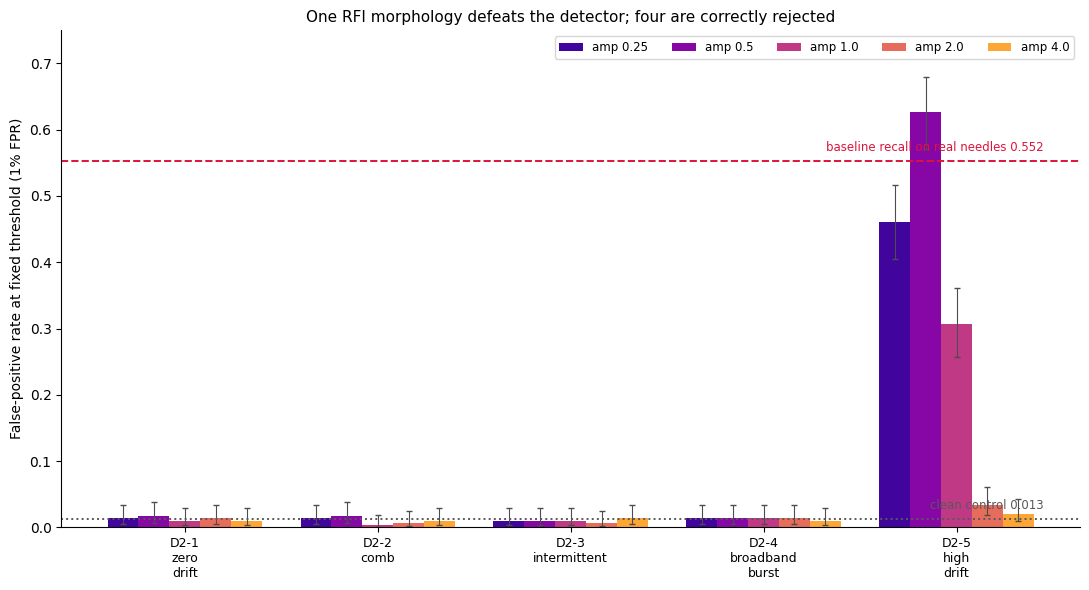

In [23]:
d2 = g[g.direction == 2]
ORDER2 = ['D2-1_zero_drift','D2-2_comb','D2-3_intermittent',
          'D2-4_broadband_burst','D2-5_high_drift']
LAB2 = ['D2-1\nzero\ndrift','D2-2\ncomb','D2-3\nintermittent',
        'D2-4\nbroadband\nburst','D2-5\nhigh\ndrift']

x, w = np.arange(5), 0.16
fig, ax = plt.subplots(figsize=(11, 6))
cmap = plt.cm.plasma(np.linspace(0.1, 0.8, len(AMPS)))

for k, amp in enumerate(AMPS):
    r = d2[d2.amplitude == amp].set_index("family").loc[ORDER2]
    ax.bar(x + (k-2)*w, r.rate, w, color=cmap[k], label=f"amp {amp}",
           yerr=[r.rate - r.lo, r.hi - r.rate],
           error_kw=dict(lw=0.8, capsize=2, ecolor='0.3'))

ax.axhline(0.5525, ls='--', c='crimson', lw=1.4)
ax.text(4.45, 0.5525+.015, 'baseline recall on real needles 0.552',
        color='crimson', fontsize=8.5, ha='right')
ax.axhline(0.013, ls=':', c='0.35', lw=1.4)
ax.text(4.45, 0.013+.015, 'clean control 0.013', color='0.35', fontsize=8.5, ha='right')

ax.set_xticks(x); ax.set_xticklabels(LAB2, fontsize=9)
ax.set_ylabel("False-positive rate at fixed threshold (1% FPR)")
ax.set_ylim(0, 0.75); ax.legend(fontsize=8.5, ncol=5)
ax.spines[['top','right']].set_visible(False)
ax.set_title("One RFI morphology defeats the detector; four are correctly rejected", fontsize=11)
plt.tight_layout()
plt.savefig("/kaggle/working/plotB_fpr_by_family.png", dpi=200, bbox_inches='tight')
plt.show()

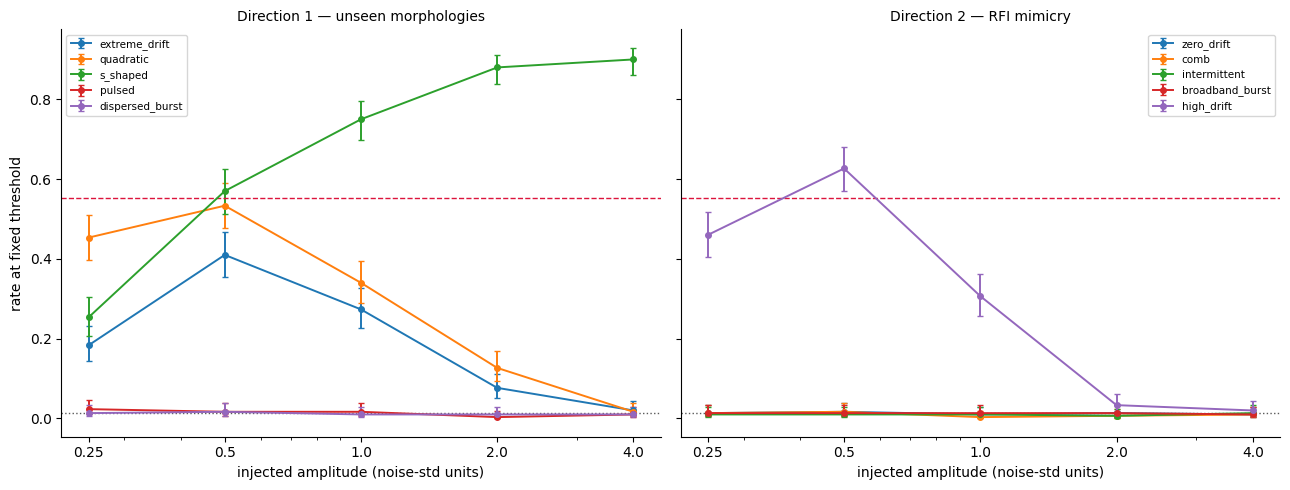

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for a, (d, order, lab, ttl) in zip(ax, [
        (1, ORDER,  'Recall', 'Direction 1 — unseen morphologies'),
        (2, ORDER2, 'False-positive rate', 'Direction 2 — RFI mimicry')]):
    sub = g[g.direction == d]
    for fam in order:
        r = sub[sub.family == fam].sort_values("amplitude")
        a.errorbar(r.amplitude, r.rate,
                   yerr=[r.rate-r.lo, r.hi-r.rate],
                   marker='o', ms=4, lw=1.4, capsize=2, label=fam.split('_',1)[1])
    a.axhline(0.5525, ls='--', c='crimson', lw=1)
    a.axhline(0.013, ls=':', c='0.35', lw=1)
    a.set_xscale('log'); a.set_xticks(AMPS); a.set_xticklabels(AMPS)
    a.set_xlabel("injected amplitude (noise-std units)")
    a.set_title(ttl, fontsize=10); a.legend(fontsize=7.5)
    a.spines[['top','right']].set_visible(False)
ax[0].set_ylabel("rate at fixed threshold")
plt.tight_layout()
plt.savefig("/kaggle/working/plotC_rate_vs_amplitude.png", dpi=200, bbox_inches='tight')
plt.show()

## PHASE 4 — GRAD-CAM

In [25]:
model.eval()
print("training mode:", model.training)
print("any param requires_grad:", any(p.requires_grad for p in model.parameters()))

training mode: False
any param requires_grad: True


In [26]:
# Purpose: verify the environment is in the exact state Phase 4 assumes.
import torch
model.eval()
checks = {
    "model in eval mode"   : model.training is False,
    "grads enabled"        : any(p.requires_grad for p in model.parameters()),
    "grad enabled globally": torch.is_grad_enabled(),
    "model on GPU"         : next(model.parameters()).is_cuda,
    "manifest 15k rows"    : man.shape == (15000, 9),
    "source cache = 300"   : len(SRC) == 300,
}
for k, v in checks.items():
    print(f"{'OK  ' if v else 'FAIL'}  {k}")
print("\nGPU:", torch.cuda.get_device_name(0))   # want Tesla T4, NOT P100

OK    model in eval mode
OK    grads enabled
OK    grad enabled globally
OK    model on GPU
OK    manifest 15k rows
OK    source cache = 300

GPU: Tesla T4


In [27]:
# Purpose: print the module structure so we can choose deep/mid/early Grad-CAM
# targets by exact name. Prints top-level children, then a trimmed list of conv
# leaves (first 8, last 8, plus mid-network anchors).
import torch.nn as nn

print("=== TOP-LEVEL CHILDREN ===")
for name, child in model.named_children():
    print(f"  {name:22s} {type(child).__name__}")

convs = [(n, m) for n, m in model.named_modules() if isinstance(m, nn.Conv2d)]
print(f"\n=== CONV2D LEAVES (total {len(convs)}) ===")
for i, (n, m) in enumerate(convs):
    keep = i < 8 or i >= len(convs) - 8 or any(k in n for k in ['blocks.2.0', 'blocks.4.0', 'blocks.5.0'])
    if keep:
        print(f"  [{i:3d}] {n:58s} in={m.in_channels:4d} out={m.out_channels:4d} k={m.kernel_size}")

=== TOP-LEVEL CHILDREN ===
  cnn                    EfficientNet
  block1                 Sequential
  block2                 Sequential
  block3                 Sequential
  block4                 Sequential
  fc                     Linear

=== CONV2D LEAVES (total 87) ===
  [  0] cnn.conv_stem                                              in=   1 out=  32 k=(3, 3)
  [  1] cnn.blocks.0.0.conv_dw                                     in=  32 out=  32 k=(3, 3)
  [  2] cnn.blocks.0.0.se.conv_reduce                              in=  32 out=   8 k=(1, 1)
  [  3] cnn.blocks.0.0.se.conv_expand                              in=   8 out=  32 k=(1, 1)
  [  4] cnn.blocks.0.0.conv_pw                                     in=  32 out=  16 k=(1, 1)
  [  5] cnn.blocks.1.0.conv_pw                                     in=  16 out=  96 k=(1, 1)
  [  6] cnn.blocks.1.0.conv_dw                                     in=  96 out=  96 k=(3, 3)
  [  7] cnn.blocks.1.0.se.conv_reduce                              in=  96

In [28]:
# Purpose: run one real sample forward and record the output shape of each
# candidate layer, to learn the true spatial resolution of each Grad-CAM target.
CANDIDATES = ['block1.0', 'block2.0', 'block3.0', 'block4.0',
              'cnn.conv_stem', 'cnn.blocks.2.0.conv_pwl',
              'cnn.blocks.4.0.conv_pwl', 'cnn.blocks.6.0.conv_pwl', 'cnn.conv_head']

mods   = dict(model.named_modules())
shapes = {}
hooks  = [mods[n].register_forward_hook(
              lambda m, i, o, n=n: shapes.__setitem__(n, tuple(o.shape)))
          for n in CANDIDATES]

row = man[(man.family.str.startswith('D1-2')) & (man.amplitude == 0.5)].iloc[0]
arr = regenerate(row, base=SRC[row.source_id])[::2].astype(np.float32)   # (3,273,256)
x   = np.vstack(arr).transpose((1, 0))                                    # (256,819)
x   = cv2.resize(x, (512, 512))
_   = model(torch.from_numpy(x)[None, None].float().to(device))
for h in hooks: h.remove()

print(f"{'layer':30s} {'shape':22s} {'freq/cell':>10s} {'time/cell':>10s}")
for n in CANDIDATES:
    s = shapes[n]
    H, W = s[2], s[3]
    print(f"{n:30s} {str(s):22s} {256/H:10.1f} {819/W:10.1f}")

layer                          shape                   freq/cell  time/cell
block1.0                       (1, 16, 508, 508)             0.5        1.6
block2.0                       (1, 16, 256, 256)             1.0        3.2
block3.0                       (1, 16, 256, 256)             1.0        3.2
block4.0                       (1, 1, 256, 256)              1.0        3.2
cnn.conv_stem                  (1, 32, 128, 128)             2.0        6.4
cnn.blocks.2.0.conv_pwl        (1, 40, 32, 32)               8.0       25.6
cnn.blocks.4.0.conv_pwl        (1, 112, 16, 16)             16.0       51.2
cnn.blocks.6.0.conv_pwl        (1, 320, 8, 8)               32.0      102.4
cnn.conv_head                  (1, 1280, 8, 8)              32.0      102.4


In [29]:
import numpy as np, cv2, torch

class GradCAM:
    def __init__(self, model, layer_name):
        self.model = model
        self.acts, self.grads = None, None
        layer = dict(model.named_modules())[layer_name]
        self.h1 = layer.register_forward_hook(lambda m, i, o: setattr(self, 'acts', o))
        self.h2 = layer.register_full_backward_hook(
            lambda m, gi, go: setattr(self, 'grads', go[0].detach()))

    def remove(self):
        self.h1.remove(); self.h2.remove()

    def raw(self):
        w = self.grads.mean(dim=(2, 3), keepdim=True)
        return (w * self.acts).sum(1)[0].detach().cpu().numpy()

    def __call__(self, arr):
        x = np.vstack(arr.astype(np.float32)).transpose((1, 0))
        x = cv2.resize(x, (512, 512))
        x = torch.from_numpy(x)[None, None].float().to(device)
        self.model.zero_grad()
        logit = self.model(x)
        logit[0, 0].backward()
        cam = np.maximum(self.raw(), 0)
        return cv2.resize(cam, (512, 512)), torch.sigmoid(logit)[0, 0].item()

In [30]:
# Purpose: confirm GradCAM's forward pass reproduces the Phase 3 scoring recipe
# exactly. If these disagree, preprocessing has drifted and every autopsy would be
# explaining a different model than the one the results describe.

@torch.no_grad()
def score_reference(arr):
    x = np.vstack(arr.astype(np.float32)).transpose((1, 0))
    x = cv2.resize(x, (512, 512))
    x = torch.from_numpy(x)[None, None].float().to(device)
    return torch.sigmoid(model(x))[0, 0].item()

_g = GradCAM(model, LAYER)
try:
    rows = man[(man.family.str.startswith('D1-2')) & (man.amplitude == 0.5)].head(5)
    print("sample_id                       gradcam    reference     diff")
    for _, r in rows.iterrows():
        a = regenerate(r, base=SRC[r.source_id])[::2].astype(np.float32)
        cam, s_cam = _g(a)
        s_ref = score_reference(a)
        print(str(r.sample_id).rjust(28),
              round(s_cam, 5), "  ", round(s_ref, 5), "  ", abs(s_cam - s_ref))
    print()
    print("cam shape:", cam.shape)
    print("raw min:", _g.raw().min(), " raw max:", _g.raw().max())
finally:
    _g.remove()

sample_id                       gradcam    reference     diff
  D1-2_quadratic_amp0.5_0000 0.48938    0.48938    0.0
  D1-2_quadratic_amp0.5_0001 0.07209    0.07209    0.0
  D1-2_quadratic_amp0.5_0002 0.07761    0.07761    0.0
  D1-2_quadratic_amp0.5_0003 0.30568    0.30568    0.0
  D1-2_quadratic_amp0.5_0004 0.15202    0.15202    0.0

cam shape: (512, 512)
raw min: -0.009813672  raw max: 0.010262471


In [31]:
r = man[(man.family.str.startswith('D1-2')) & (man.amplitude == 0.5)].iloc[0]
a = regenerate(r, base=SRC[r.source_id])[::2].astype(np.float32)
lo, hi = r.freq_pos, r.freq_pos + 60
print(f"sample {r.sample_id}   signal spans freq {lo:.0f} to {hi:.0f}")

for name in ['cnn.conv_head', 'cnn.blocks.4.0.conv_pwl', 'cnn.blocks.2.0.conv_pwl']:
    g = GradCAM(model, name)
    _, s = g(a)
    raw = g.raw()
    g.remove()
    H = raw.shape[0]
    prof = np.abs(raw).sum(1)
    rows = np.arange(H) * 256 / H
    inband = (rows >= lo) & (rows < hi)
    ratio = prof[inband].mean() / prof[~inband].mean()
    print()
    print(f"{name}   grid {raw.shape}   score {s:.4f}")
    print(f"  positive cells : {(raw>0).sum():4d} / {raw.size}")
    print(f"  pre-relu range : {raw.min():.3e} to {raw.max():.3e}")
    print(f"  in-band mass ratio: {ratio:.2f}   (>1.5 = signal is represented)")

sample D1-2_quadratic_amp0.5_0000   signal spans freq 124 to 184

cnn.conv_head   grid (8, 8)   score 0.4894
  positive cells :   64 / 64
  pre-relu range : 1.940e-03 to 4.897e-02
  in-band mass ratio: 1.48   (>1.5 = signal is represented)

cnn.blocks.4.0.conv_pwl   grid (16, 16)   score 0.4894
  positive cells :  127 / 256
  pre-relu range : -3.405e-03 to 1.134e-02
  in-band mass ratio: 2.21   (>1.5 = signal is represented)

cnn.blocks.2.0.conv_pwl   grid (32, 32)   score 0.4894
  positive cells :    6 / 1024
  pre-relu range : -1.318e-02 to 8.897e-04
  in-band mass ratio: 1.19   (>1.5 = signal is represented)


In [32]:
rows = man[(man.family.str.startswith('D1-2')) & (man.amplitude == 0.5)].head(25)
g = GradCAM(model, 'cnn.blocks.4.0.conv_pwl')

res = []
for _, r in rows.iterrows():
    a = regenerate(r, base=SRC[r.source_id])[::2].astype(np.float32)
    _, s = g(a)
    raw = g.raw()
    H = raw.shape[0]
    prof = np.abs(raw).sum(1)
    fr = np.arange(H) * 256 / H
    inb = (fr >= r.freq_pos) & (fr < r.freq_pos + 60)
    res.append((s, prof[inb].mean() / prof[~inb].mean()))
g.remove()

res = np.array(res)
det, mis = res[res[:,0] > 0.1309], res[res[:,0] <= 0.1309]
print(f"detected (n={len(det)}): mean ratio {det[:,1].mean():.2f}   range {det[:,1].min():.2f}-{det[:,1].max():.2f}")
print(f"missed   (n={len(mis)}): mean ratio {mis[:,1].mean():.2f}   range {mis[:,1].min():.2f}-{mis[:,1].max():.2f}")

detected (n=13): mean ratio 1.65   range 0.99-2.70
missed   (n=12): mean ratio 1.09   range 0.78-1.55


In [33]:
from scipy.stats import mannwhitneyu
u, p = mannwhitneyu(det[:,1], mis[:,1], alternative='greater')
print(f"Mann-Whitney U p = {p:.2e}")
print(f"median detected {np.median(det[:,1]):.2f}  vs  missed {np.median(mis[:,1]):.2f}")

Mann-Whitney U p = 3.01e-03
median detected 1.49  vs  missed 1.08


In [34]:
from scipy.stats import spearmanr
rho, pr = spearmanr(res[:,0], res[:,1])
print(f"score vs ratio: rho = {rho:.3f}, p = {pr:.2e}")

score vs ratio: rho = 0.638, p = 6.06e-04


In [35]:
# Purpose: Adebayo model-randomisation sanity check. If a heatmap survives the
# destruction of the learned weights, it is an edge detector responding to image
# structure, not an explanation of the model. The 'full' row is the verdict.
import copy
from scipy.stats import spearmanr as sr

def strip_hooks(m):
    """deepcopy carries hooks across — without this the COPY writes into the
    ORIGINAL's GradCAM object, and the test silently compares the copy to itself."""
    for mod in m.modules():
        mod._forward_hooks.clear()
        mod._backward_hooks.clear()
        if hasattr(mod, '_full_backward_hooks'):
            mod._full_backward_hooks.clear()

def randomize(scope):
    rm = copy.deepcopy(model)                         # NEVER touch the frozen model
    strip_hooks(rm)
    if scope == 'downstream':                         # after the probed layer
        mods = list(rm.cnn.blocks[5:].modules()) + list(rm.cnn.conv_head.modules())
    elif scope == 'upstream':                         # feeds the probed layer
        mods = list(rm.cnn.conv_stem.modules()) + list(rm.cnn.blocks[:5].modules())
    else:                                             # 'full' — everything
        mods = list(rm.modules())
    for m in mods:
        if hasattr(m, 'reset_parameters'):
            m.reset_parameters()
    rm.eval()
    return rm

rows = man[(man.family.str.startswith('D1-2')) & (man.amplitude == 0.5)].head(10)

for scope in ['downstream', 'upstream', 'full']:
    rm = randomize(scope)
    gA, gB = GradCAM(model, LAYER), GradCAM(rm, LAYER)
    try:
        cors, scores = [], []
        for _, r in rows.iterrows():
            a = regenerate(r, base=SRC[r.source_id])[::2].astype(np.float32)
            gA(a); A = gA.raw().copy()                # copy BEFORE the next forward pass
            _, s1 = gB(a); B = gB.raw().copy()
            cors.append(sr(A.ravel(), B.ravel()).correlation)
            scores.append(s1)
    finally:
        gA.remove(); gB.remove()
    print(f"{scope:11s} corr {np.mean(cors):+.3f}  range {min(cors):+.3f}..{max(cors):+.3f}"
          f"   rand score {np.mean(scores):.4f}")

downstream  corr +0.379  range +0.037..+0.649   rand score 0.1015
upstream    corr +0.127  range -0.109..+0.463   rand score 0.0397
full        corr -0.113  range -0.340..+0.107   rand score 0.4944


In [36]:
import os, pandas as pd
OUT = "/kaggle/working/phase3_scores.csv"
print("exists:", os.path.exists(OUT))
if os.path.exists(OUT):
    print("rows:", len(pd.read_csv(OUT)), "(want 15000)")

exists: True
rows: 15000 (want 15000)


In [37]:
# Purpose: Step 4.1 — rule-based autopsy cohort selection.
# Rules are fixed BEFORE any heatmap is generated. Selection is deterministic
# (top-N by score, or seeded random). Once saved, the cohort is LOADED, never
# re-picked — the same 72 samples must be used in every later session and cited
# in Methods.
import os, glob, shutil
import numpy as np, pandas as pd

N_PER_GROUP = 12
COHORT_SEED = 4141
COHORT_PATH = "/kaggle/working/phase4_cohort.csv"

PRIOR = glob.glob("/kaggle/input/**/phase4_cohort.csv", recursive=True)
if PRIOR and not os.path.exists(COHORT_PATH):
    shutil.copy(PRIOR[0], COHORT_PATH)
    print("loaded saved cohort from", PRIOR[0])

if os.path.exists(COHORT_PATH):
    cohort = pd.read_csv(COHORT_PATH)
    print("cohort already fixed — not re-picking")
else:
    sc = pd.read_csv("/kaggle/working/phase3_scores.csv")
    df = man.merge(sc, on="sample_id")

    def pick(group, family, amp, mode, n=N_PER_GROUP):
        s = df[(df.family == family) & (np.isclose(df.amplitude, amp))]
        if mode == 'top_detected':
            s = s[s.score > THRESHOLD].nlargest(n, 'score')
        elif mode == 'bottom_missed':
            s = s[s.score <= THRESHOLD].nsmallest(n, 'score')
        else:
            s = s.sample(min(n, len(s)), random_state=COHORT_SEED)
        out = s.copy()
        out['group'] = group
        out['rule'] = mode
        return out

    RULES = [
        ('Q1_fool',        'D2-5_high_drift',      0.5, 'top_detected'),
        ('Q1c_true_det',   'D1-2_quadratic',       0.5, 'top_detected'),
        ('Q2_bright_hit',  'D1-3_s_shaped',        4.0, 'top_detected'),
        ('Q2c_bright_mis', 'D1-1_extreme_drift',   4.0, 'bottom_missed'),
        ('Q3_pulsed',      'D1-4_pulsed',          4.0, 'random_any'),
        ('Q3_dispersed',   'D1-5_dispersed_burst', 4.0, 'random_any'),
    ]

    cohort = pd.concat([pick(*r) for r in RULES], ignore_index=True)
    cohort.to_csv(COHORT_PATH, index=False)
    print("cohort selected fresh and saved")

for gname, g in cohort.groupby('group', sort=False):
    print(gname.ljust(16), g.family.iloc[0].ljust(24), "n =", len(g),
          "  scores", round(g.score.min(), 4), "..", round(g.score.max(), 4))
print()
print("total:", len(cohort), " unique backgrounds:", cohort.source_id.nunique())

cohort selected fresh and saved
Q1_fool          D2-5_high_drift          n = 12   scores 0.6063 .. 0.8311
Q1c_true_det     D1-2_quadratic           n = 12   scores 0.6081 .. 0.7813
Q2_bright_hit    D1-3_s_shaped            n = 12   scores 0.9484 .. 0.9869
Q2c_bright_mis   D1-1_extreme_drift       n = 12   scores 0.0166 .. 0.028
Q3_pulsed        D1-4_pulsed              n = 12   scores 0.011 .. 0.0722
Q3_dispersed     D1-5_dispersed_burst     n = 12   scores 0.0098 .. 0.0635

total: 72  unique backgrounds: 51


In [38]:
# Purpose: Step 4.2a — compute the in-band attention ratio for all 72 cohort
# samples, plus the same measure on each sample's own CLEAN background. The
# paired difference isolates what the injection changed, removing background
# variation (same logic as the S11 paired Wilcoxon).
# Loads a saved copy if one exists, so re-running costs nothing.
import os, glob, shutil
import numpy as np, pandas as pd

RATIO_PATH = "/kaggle/working/phase4_ratios.csv"

BAND = {'D1-1_extreme_drift': 60, 'D1-2_quadratic': 60, 'D1-3_s_shaped': 60,
        'D1-4_pulsed': 60, 'D1-5_dispersed_burst': 256, 'D2-5_high_drift': 45}

def inband_ratio(raw, freq_pos, span):
    """mean |CAM| inside the signal's frequency band / mean |CAM| outside it"""
    H = raw.shape[0]
    prof = np.abs(raw).sum(1)
    fr = np.arange(H) * 256 / H
    inb = (fr >= freq_pos) & (fr < freq_pos + span)
    if inb.sum() == 0 or (~inb).sum() == 0:
        return np.nan
    return prof[inb].mean() / prof[~inb].mean()

PRIOR = glob.glob("/kaggle/input/**/phase4_ratios.csv", recursive=True)
if PRIOR and not os.path.exists(RATIO_PATH):
    shutil.copy(PRIOR[0], RATIO_PATH)
    print("loaded saved ratios from", PRIOR[0])

if os.path.exists(RATIO_PATH):
    res = pd.read_csv(RATIO_PATH)
    print("ratios already computed — not recomputing")
else:
    g = GradCAM(model, LAYER)
    recs = []
    try:
        for _, r in cohort.iterrows():
            span = BAND[r.family]
            inj = regenerate(r, base=SRC[r.source_id])[::2].astype(np.float32)
            _, s_inj = g(inj)
            rat_inj = inband_ratio(g.raw(), r.freq_pos, span)

            cln = SRC[r.source_id][::2].astype(np.float32)
            _, s_cln = g(cln)
            rat_cln = inband_ratio(g.raw(), r.freq_pos, span)

            recs.append(dict(sample_id=r.sample_id, group=r.group, family=r.family,
                             score=s_inj, score_clean=s_cln,
                             ratio=rat_inj, ratio_clean=rat_cln,
                             d_ratio=rat_inj - rat_cln))
    finally:
        g.remove()
    res = pd.DataFrame(recs)
    res.to_csv(RATIO_PATH, index=False)
    print("ratios computed fresh and saved")

print()
print("group            n   score   ratio_inj  ratio_clean   delta")
for gn, gg in res.groupby('group', sort=False):
    print(gn.ljust(16), len(gg),
          " ", round(gg.score.mean(), 3),
          "   ", round(gg.ratio.mean(), 3),
          "     ", round(gg.ratio_clean.mean(), 3),
          "    ", round(gg.d_ratio.mean(), 3))

ratios computed fresh and saved

group            n   score   ratio_inj  ratio_clean   delta
Q1_fool          12   0.71     4.018       0.871      3.147
Q1c_true_det     12   0.695     1.785       0.906      0.879
Q2_bright_hit    12   0.967     1.703       1.052      0.65
Q2c_bright_mis   12   0.023     0.823       0.828      -0.004
Q3_pulsed        12   0.034     1.023       1.04      -0.017
Q3_dispersed     12   0.029     0.995       1.026      -0.031


In [39]:
# Purpose: draw one autopsy row — spectrogram | CAM overlay | difference map.
# The difference map is the informative one: CAM(injected) - CAM(clean background)
# isolates what the INJECTION changed, removing background structure.
import matplotlib.pyplot as plt

PANEL_X = [170.7, 341.3]          # ON-panel boundaries in the 512-wide image

def autopsy_row(axes, row, gcam):
    inj = regenerate(row, base=SRC[row.source_id])[::2].astype(np.float32)
    cln = SRC[row.source_id][::2].astype(np.float32)

    _, s_inj = gcam(inj);  cam_inj = cv2.resize(gcam.raw(), (512, 512))
    _, s_cln = gcam(cln);  cam_cln = cv2.resize(gcam.raw(), (512, 512))
    diff = cam_inj - cam_cln

    img = cv2.resize(np.vstack(inj).transpose((1, 0)), (512, 512))
    y_lo = row.freq_pos * 2                       # freq channel -> image y

    for ax, (data, title, cmap) in zip(axes, [
            (img,  f"input  score={s_inj:.3f}", 'viridis'),
            (cam_inj, "CAM (injected)",         'inferno'),
            (diff, "CAM diff (inj - clean)",    'seismic')]):
        if cmap == 'seismic':
            v = np.abs(data).max()
            ax.imshow(data, cmap=cmap, vmin=-v, vmax=v, aspect='auto')
        else:
            lo, hi = np.percentile(data, [2, 98])
            ax.imshow(data, cmap=cmap, vmin=lo, vmax=hi, aspect='auto')
        for x in PANEL_X:
            ax.axvline(x, color='white', lw=0.6, alpha=0.6)
        ax.axhline(y_lo, color='lime', lw=0.6, alpha=0.7)      # signal start freq
        ax.set_title(title, fontsize=8)
        ax.set_xticks([]); ax.set_yticks([])

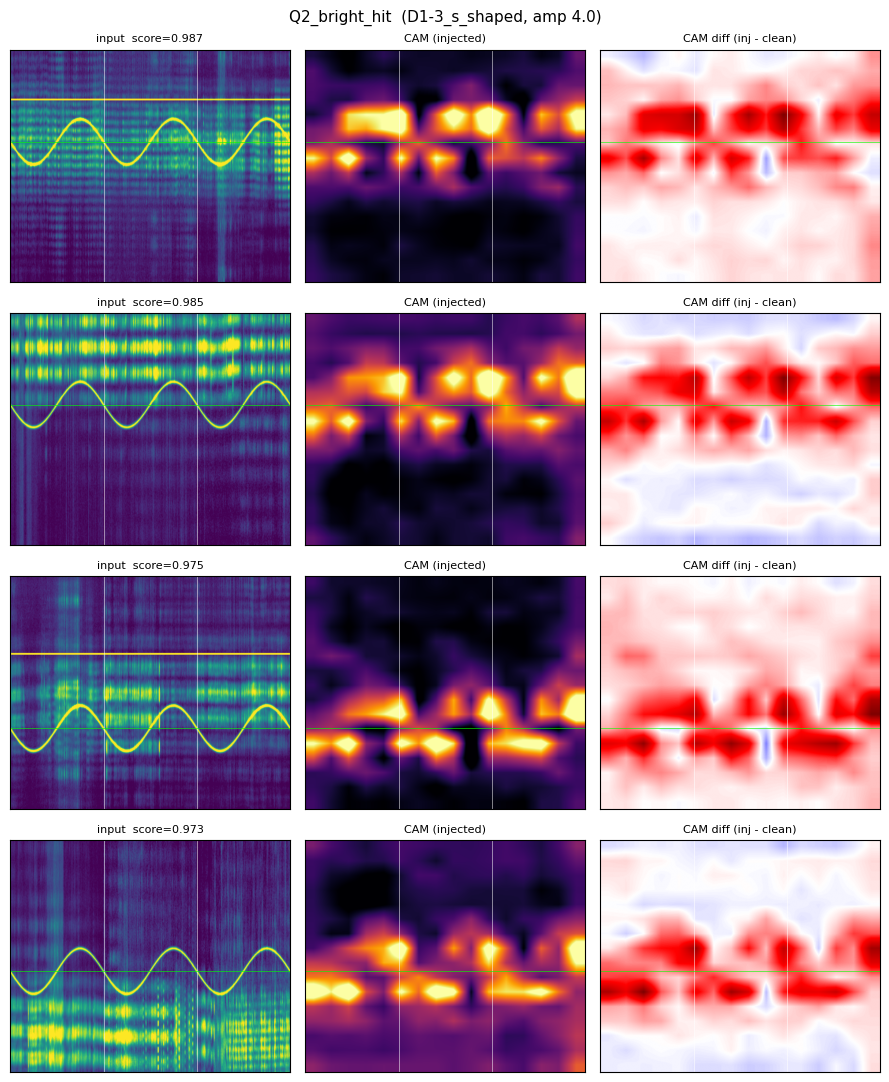

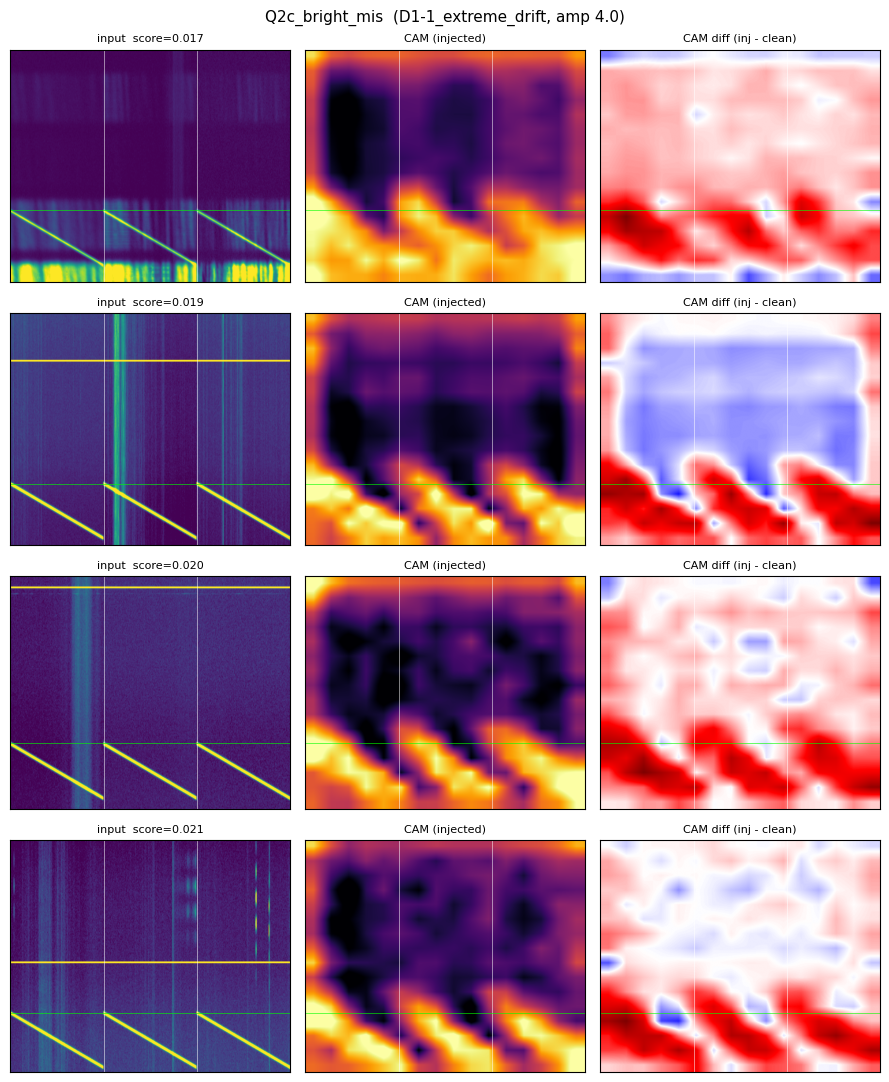

In [40]:
# Purpose: Q2 — why is a bright S-shape detected (0.967) and an equally bright
# straight line missed (0.023)? Four samples from each group, side by side.
g = GradCAM(model, LAYER)
try:
    for grp in ['Q2_bright_hit', 'Q2c_bright_mis']:
        sub = cohort[cohort.group == grp].head(4)
        fig, axs = plt.subplots(4, 3, figsize=(9, 11))
        for i, (_, r) in enumerate(sub.iterrows()):
            autopsy_row(axs[i], r, g)
        fig.suptitle(f"{grp}  ({sub.family.iloc[0]}, amp 4.0)", fontsize=11)
        plt.tight_layout()
        plt.show()
finally:
    g.remove()

In [41]:
# Purpose: test the "locally flat looks like a training needle" hypothesis for
# D1-3 s_shaped. Walk along the signal's TRUE path, record the CAM value and the
# local slope at each point, and check whether attention concentrates where the
# path is flat. NEGATIVE correlation supports the hypothesis.
from scipy.stats import spearmanr

def slope_test(group):
    g = GradCAM(model, LAYER)
    rhos = []
    try:
        for _, r in cohort[cohort.group == group].iterrows():
            inj = regenerate(r, base=SRC[r.source_id])[::2].astype(np.float32)
            cln = SRC[r.source_id][::2].astype(np.float32)
            g(inj)
            cam = cv2.resize(g.raw(), (512, 512))

            path = (inj - cln).argmax(axis=2)        # (3,273): freq index per time row
            vals, slopes = [], []
            for p in range(3):
                fr = path[p].astype(float)
                sl = np.abs(np.gradient(fr))
                for t in range(5, 268):
                    x = int((p * 273 + t) * 512 / 819)
                    y = int(fr[t] * 2)
                    if 0 <= y < 512 and 0 <= x < 512:
                        vals.append(cam[y, x])
                        slopes.append(sl[t])
            rhos.append(spearmanr(slopes, vals).correlation)
    finally:
        g.remove()
    return np.array(rhos)

r_s = slope_test('Q2_bright_hit')
print("D1-3 s_shaped, CAM vs |slope| rank correlation per sample:")
print(np.round(r_s, 3))
print("mean:", round(float(np.mean(r_s)), 3),
      "  n negative:", int((r_s < 0).sum()), "/", len(r_s))

D1-3 s_shaped, CAM vs |slope| rank correlation per sample:
[ 0.007  0.009  0.089 -0.132  0.128 -0.221 -0.224  0.142 -0.008  0.047
 -0.079  0.08 ]
mean: -0.014   n negative: 5 / 12


In [42]:
# Purpose: Q2 — is the difference CONCENTRATION rather than presence? Both groups
# attend to the signal; the S-shape response looked tighter. Measure how unevenly
# each response is distributed across the map.
def concentration(group):
    g = GradCAM(model, LAYER)
    top10, gini, total = [], [], []
    try:
        for _, r in cohort[cohort.group == group].iterrows():
            inj = regenerate(r, base=SRC[r.source_id])[::2].astype(np.float32)
            cln = SRC[r.source_id][::2].astype(np.float32)
            g(inj); a = g.raw().copy()
            g(cln); c = g.raw().copy()
            d = np.abs(a - c).ravel()

            s = np.sort(d)
            k = max(1, int(0.10 * len(s)))
            top10.append(s[-k:].sum() / s.sum())

            n = len(s)
            idx = np.arange(1, n + 1)
            gini.append((2 * (idx * s).sum()) / (n * s.sum()) - (n + 1) / n)

            total.append(d.sum())
    finally:
        g.remove()
    return np.array(top10), np.array(gini), np.array(total)

for grp in ['Q2_bright_hit', 'Q2c_bright_mis']:
    t10, gn, tot = concentration(grp)
    print(grp.ljust(16),
          " top10% mass", round(float(t10.mean()), 3),
          "  gini", round(float(gn.mean()), 3),
          "  total |Δ|", format(float(tot.mean()), '.3e'))

Q2_bright_hit     top10% mass 0.414   gini 0.589   total |Δ| 1.534e+00
Q2c_bright_mis    top10% mass 0.358   gini 0.536   total |Δ| 5.337e-01


In [43]:
# Purpose: measure total |Δ CAM| per group — a DILUTION-FREE alternative to the
# in-band ratio. No denominator, so a wide bright CAM cannot drag it toward 1.
# Q2 groups are RECOMPUTED here as reference arms, not read from the S14 log.
GROUPS_43 = ['Q3_pulsed', 'Q3_dispersed', 'Q2_bright_hit', 'Q2c_bright_mis']

def cam_diff_raw(row, gcam):
    """Paired CAM difference for one manifest row, on the RAW 16x16 map.
    `row` must be a pandas Series — regenerate() indexes with row['family']."""
    inj = regenerate(row, base=SRC[row.source_id])[::2].astype(np.float32)
    cln = SRC[row.source_id][::2].astype(np.float32)
    gcam(inj); a = gcam.raw().copy()     # .copy() — next forward overwrites it
    gcam(cln); b = gcam.raw().copy()
    return a - b

totals = {}
g = GradCAM(model, LAYER)
try:
    for grp in GROUPS_43:
        rows = cohort[cohort.group == grp]
        vals = [np.abs(cam_diff_raw(r, g)).sum() for _, r in rows.iterrows()]
        totals[grp] = float(np.mean(vals))
        print(f"{grp:18s} n={len(vals):2d}  mean total |dCAM| = {totals[grp]:.3f}")
finally:
    g.remove()

ref = totals['Q2c_bright_mis']
print(f"\nQ2 hit / Q2c ratio = {totals['Q2_bright_hit']/ref:.2f}   (S14 gave 2.87)")
for grp in ['Q3_pulsed', 'Q3_dispersed']:
    print(f"{grp:18s} ratio to Q2c = {totals[grp]/ref:.2f}")

Q3_pulsed          n=12  mean total |dCAM| = 0.249
Q3_dispersed       n=12  mean total |dCAM| = 0.152
Q2_bright_hit      n=12  mean total |dCAM| = 1.534
Q2c_bright_mis     n=12  mean total |dCAM| = 0.534

Q2 hit / Q2c ratio = 2.87   (S14 gave 2.87)
Q3_pulsed          ratio to Q2c = 0.47
Q3_dispersed       ratio to Q2c = 0.29


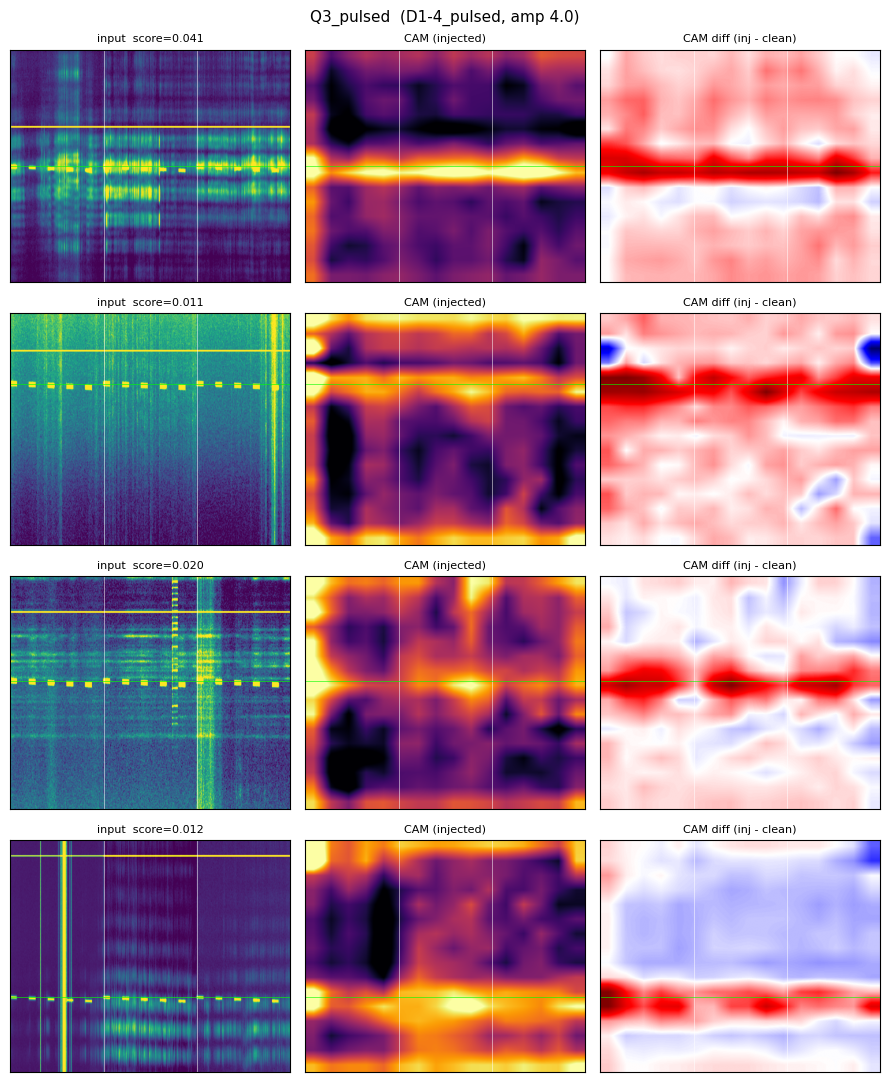

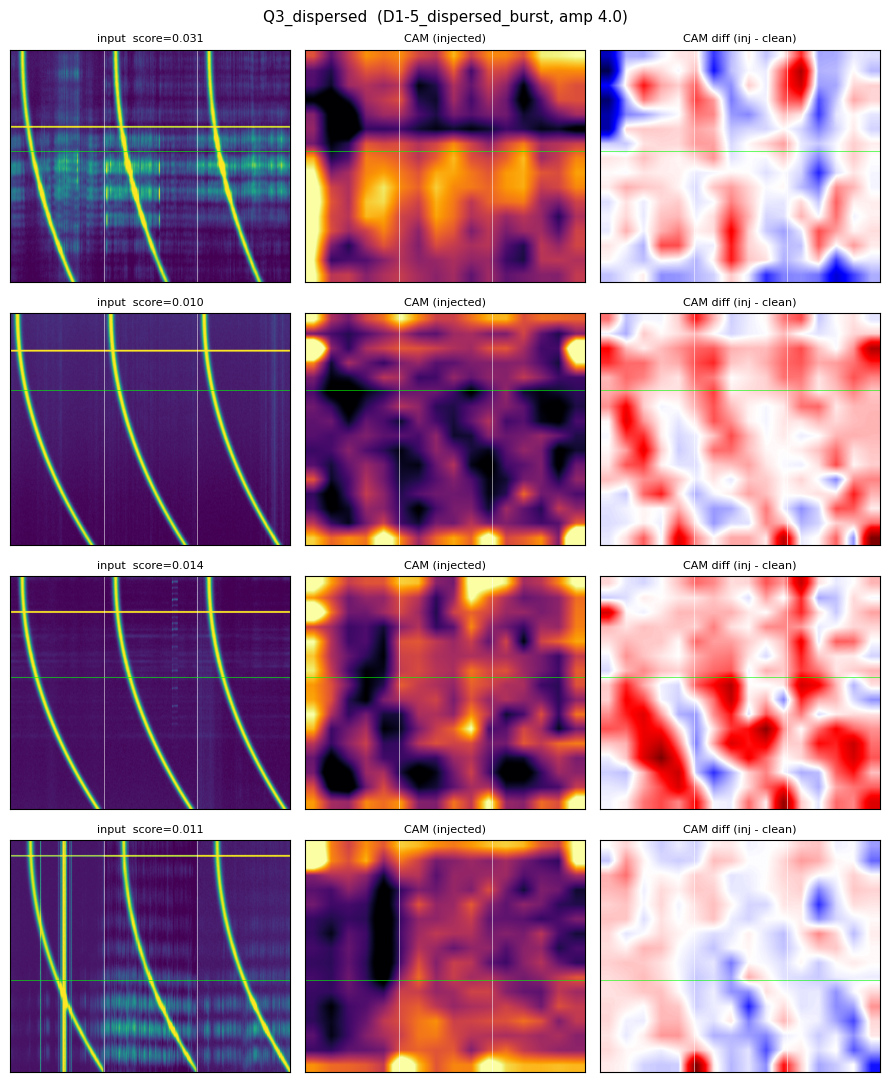

In [44]:
# Purpose: Q3 verification — render pulsed and dispersed autopsies. The magnitude
# test put pulsed in the pre-declared undecidable band (0.47 x Q2c), so these
# images are the deciding evidence. Judge STRUCTURE (does it follow the signal
# path?), never vividness — the seismic scale auto-stretches to the map's max.
g = GradCAM(model, LAYER)
try:
    for grp in ['Q3_pulsed', 'Q3_dispersed']:
        sub = cohort[cohort.group == grp].head(4)
        fig, axs = plt.subplots(4, 3, figsize=(9, 11))
        for i, (_, r) in enumerate(sub.iterrows()):
            autopsy_row(axs[i], r, g)
        fig.suptitle(f"{grp}  ({sub.family.iloc[0]}, amp 4.0)", fontsize=11)
        plt.tight_layout()
        plt.show()
finally:
    g.remove()

In [45]:
print(cohort[cohort.group=='Q3_pulsed'].head(4)[['freq_pos','score']])

    freq_pos     score
48  128.6517  0.041370
49   78.0032  0.011020
50  114.6007  0.020184
51  173.3228  0.011872


In [46]:
# Purpose: Q3_dispersed — is the response FOLLOWING the arc, or is it noise that
# looks arc-like? Compare mean |dCAM| on each sample's TRUE arc against the same
# sample's map sampled along OTHER samples' arcs (same magnitude, wrong path).
def arc_mask(row, shape=(512, 512)):
    """Boolean mask of the dispersed burst's path in image coords."""
    rng = np.random.default_rng(int(row['seed']))
    t0, sweep = rng.uniform(10, 80), rng.uniform(120, 240)     # matches generator
    m = np.zeros(shape, bool)
    for y in range(shape[0]):
        f = y / 2                                   # image y -> freq channel
        t = t0 + sweep * (f / 256.0) ** 2           # arrival time, in rows
        if t >= 273: continue                       # ran off the panel edge
        for p in range(3):                          # same arc in all 3 ON panels
            x = int((t + p * 273) * 512 / 819)
            m[y, max(0, x-3):x+4] = True            # +/-3 px tolerance
    return m

g = GradCAM(model, LAYER)
try:
    sub  = cohort[cohort.group == 'Q3_dispersed']
    maps = [np.abs(cv2.resize(cam_diff_raw(r, g), (512, 512))) for _, r in sub.iterrows()]
    masks = [arc_mask(r) for _, r in sub.iterrows()]
finally:
    g.remove()

true_v, null_v = [], []
for i, m in enumerate(maps):
    true_v.append(m[masks[i]].mean())
    null_v.append(np.mean([m[masks[j]].mean() for j in range(len(maps)) if j != i]))

from scipy.stats import wilcoxon
true_v, null_v = np.array(true_v), np.array(null_v)
print(f"on TRUE arc  : {true_v.mean():.4f}")
print(f"on OTHER arcs: {null_v.mean():.4f}")
print(f"ratio        : {true_v.mean()/null_v.mean():.2f}")
print(f"paired Wilcoxon p = {wilcoxon(true_v, null_v).pvalue:.2e}   ({(true_v>null_v).sum()}/12 positive)")

on TRUE arc  : 0.0008
on OTHER arcs: 0.0007
ratio        : 1.15
paired Wilcoxon p = 3.42e-03   (11/12 positive)


In [47]:
# Purpose: same on-path test for D1-4 pulsed. The retraction currently rests on
# eyeballing 4 figures; this puts a number on it. Null is cleaner here than for
# dispersed — freq_pos spans 78-173, so other samples' paths sit at different heights.
def line_mask(row, shape=(512, 512)):
    m = np.zeros(shape, bool)
    on = (np.arange(273) % 55) < (55 * 0.35)          # duty cycle, matches generator
    for t in range(273):
        if not on[t]: continue
        y = int((row['freq_pos'] + 5.0 * (t / 273)) * 2)
        if not (0 <= y < 512): continue
        for p in range(3):
            x = int((t + p * 273) * 512 / 819)
            m[max(0, y-3):y+4, x] = True
    return m

g = GradCAM(model, LAYER)
try:
    sub  = cohort[cohort.group == 'Q3_pulsed']
    maps = [np.abs(cv2.resize(cam_diff_raw(r, g), (512, 512))) for _, r in sub.iterrows()]
    masks = [line_mask(r) for _, r in sub.iterrows()]
finally:
    g.remove()

t_v = np.array([m[masks[i]].mean() for i, m in enumerate(maps)])
n_v = np.array([np.mean([m[masks[j]].mean() for j in range(len(maps)) if j != i])
                for i, m in enumerate(maps)])
print(f"on TRUE path : {t_v.mean():.4f}\non OTHER paths: {n_v.mean():.4f}")
print(f"ratio: {t_v.mean()/n_v.mean():.2f}   p = {wilcoxon(t_v, n_v).pvalue:.2e}   ({(t_v>n_v).sum()}/12)")

on TRUE path : 0.0031
on OTHER paths: 0.0011
ratio: 2.81   p = 4.88e-04   (12/12)


In [48]:
# Purpose: on-path test for D1-1 extreme_drift @ amp 4.0 (Q2c_bright_mis). The
# S14 "attended but not detected" reading for this family rests on IMAGES only;
# D1-4 showed that is not enough. Same instrument as cells 53/54.
# PRE-REGISTERED RULE (same as S15): ratio > 1.3 AND >= 9/12 positive.
def drift_mask(row, shape=(512, 512)):
    """Boolean mask of D1-1's straight path: freq_pos + 60*(t/273), all rows."""
    m = np.zeros(shape, bool)
    for t in range(273):
        y = int((row['freq_pos'] + 60.0 * (t / 273)) * 2)   # freq ch -> image y
        if not (0 <= y < 512): continue
        for p in range(3):                                   # same line, 3 ON panels
            x = int((t + p * 273) * 512 / 819)               # stacked col -> image x
            m[max(0, y-3):y+4, x] = True
    return m

sub = cohort[cohort.group == 'Q2c_bright_mis']
print("freq_pos spread:", sub.freq_pos.round(1).tolist())
print(f"range {sub.freq_pos.min():.1f} .. {sub.freq_pos.max():.1f}  "
      f"(~{(sub.freq_pos.max()-sub.freq_pos.min())*2/32:.1f} CAM cells)\n")

g = GradCAM(model, LAYER)
try:
    maps  = [np.abs(cv2.resize(cam_diff_raw(r, g), (512, 512))) for _, r in sub.iterrows()]
    masks = [drift_mask(r) for _, r in sub.iterrows()]
finally:
    g.remove()

t_v = np.array([m[masks[i]].mean() for i, m in enumerate(maps)])
n_v = np.array([np.mean([m[masks[j]].mean() for j in range(len(maps)) if j != i])
                for i, m in enumerate(maps)])
print(f"on TRUE path  : {t_v.mean():.4f}\non OTHER paths: {n_v.mean():.4f}")
print(f"ratio: {t_v.mean()/n_v.mean():.2f}   p = {wilcoxon(t_v, n_v).pvalue:.2e}   "
      f"({(t_v>n_v).sum()}/12 positive)")
print("per-sample ratios:", np.round(t_v/n_v, 2).tolist())

freq_pos spread: [177.1, 188.0, 183.7, 190.5, 184.2, 168.4, 182.4, 180.1, 164.6, 180.6, 186.0, 175.4]
range 164.6 .. 190.5  (~1.6 CAM cells)

on TRUE path  : 0.0059
on OTHER paths: 0.0056
ratio: 1.06   p = 1.76e-01   (9/12 positive)
per-sample ratios: [1.149999976158142, 0.949999988079071, 1.0199999809265137, 1.0099999904632568, 1.0499999523162842, 1.3899999856948853, 0.9599999785423279, 1.0299999713897705, 1.5399999618530273, 1.0399999618530273, 0.9300000071525574, 1.1399999856948853]


In [49]:
# Purpose: Step 4.3a — OCCLUSION cross-check. Interventional: erase the injected
# band (replace with the same source's clean pixels), re-score, measure the drop.
# Breaks the circularity caveat (attention vs score are both read-outs; this is
# an intervention on the INPUT) and is the second saliency method (Adebayo 2018).
#
# PRE-REGISTERED (S16, before running):
#   Detected groups (Q1_fool, Q1c_true_det, Q2_bright_hit): CONFIRMED if median
#     recovered fraction >= 0.5 AND >= 9/12 samples drop.
#   Missed groups (Q2c, Q3_pulsed, Q3_dispersed): direction only, no bar.
#   Predictions: three detected groups -> large drop toward clean score.
#     Q2c / Q3_pulsed -> small move UP toward clean. Q3_dispersed -> ~no change.
import numpy as np, pandas as pd

HALF = 4   # channels either side of the true path (gaussian width 1.2 -> >99% energy)

def path_center(row, t, n=273):
    """True freq-channel centre of the injected line at time row t, from the generator."""
    f, fam = row['freq_pos'], row['family']
    if fam == 'D1-1_extreme_drift': return f + 60.0 * (t / n)
    if fam == 'D1-2_quadratic':     return f + 60.0 * (t / n) ** 2
    if fam == 'D1-3_s_shaped':      return f + 25.0 * np.sin(2 * np.pi * (t / n))
    if fam == 'D1-4_pulsed':        return f + 5.0 * (t / n)
    if fam == 'D2-5_high_drift':    return f + 45.0 * (t / n)
    raise ValueError(fam)

def band_mask(row, shape=(273, 256)):
    """Boolean (time, freq) mask of where the injection lives in ONE panel."""
    m = np.zeros(shape, bool)
    faxis = np.arange(shape[1])
    if row['family'] == 'D1-5_dispersed_burst':
        rng = np.random.default_rng(int(row['seed']))
        t0, sweep = rng.uniform(10, 80), rng.uniform(120, 240)   # matches generator
        arrival = t0 + sweep * (faxis / 256.0) ** 2
        for t in range(shape[0]):
            m[t] = np.abs(t - arrival) <= 2 * 6.0               # +/- 2*thickness
        return m
    for t in range(shape[0]):
        c = path_center(row, t)
        m[t] = np.abs(faxis - c) <= HALF
    return m

def occlude(inj6, cln6, mask):
    """Paste clean pixels over the masked band in the three ON panels."""
    out = inj6.copy()
    for j in (0, 2, 4):
        out[j][mask] = cln6[j][mask]
    return out

recs = []
for _, r in cohort.iterrows():
    cln6 = SRC[r.source_id]
    inj6 = regenerate(r, base=cln6)
    m    = band_mask(r)
    occ6 = occlude(inj6, cln6, m)
    s_inj, s_occ, s_cln = score_batch([prep_np(inj6), prep_np(occ6), prep_np(cln6)])
    gap  = s_inj - s_cln
    recs.append(dict(sample_id=r.sample_id, group=r.group, family=r.family,
                     score_inj=s_inj, score_occ=s_occ, score_clean=s_cln,
                     gap=gap, delta=s_inj - s_occ,
                     recovered=(s_inj - s_occ) / gap if abs(gap) > 1e-6 else np.nan,
                     mask_frac=m.mean()))

occ = pd.DataFrame(recs)
occ.to_csv("/kaggle/working/phase4_occlusion.csv", index=False)

print("group            inj     occ     clean   | median recovered  n_drop  mask%")
for gn, gg in occ.groupby('group', sort=False):
    print(f"{gn:16s} {gg.score_inj.mean():.4f}  {gg.score_occ.mean():.4f}  "
          f"{gg.score_clean.mean():.4f} |   {gg['recovered'].median():6.2f}      "
          f"{(gg['delta'] > 0).sum():2d}/12   {100*gg.mask_frac.mean():.1f}")

group            inj     occ     clean   | median recovered  n_drop  mask%
Q1_fool          0.7103  0.0415  0.0415 |     1.00      12/12   3.1
Q1c_true_det     0.6952  0.0449  0.0449 |     1.00      12/12   3.1
Q2_bright_hit    0.9669  0.0372  0.0372 |     1.00      12/12   3.1
Q2c_bright_mis   0.0227  0.0128  0.0128 |     1.00      12/12   3.1
Q3_pulsed        0.0342  0.0311  0.0311 |     1.00      10/12   3.1
Q3_dispersed     0.0286  0.0308  0.0311 |     0.81       5/12   8.8


In [50]:
# Purpose: Step 4.3a — DELETION CURVES. Erase 32x32 cells (the CAM grid) from the
# preprocessed 512x512 input in CAM-rank order vs random order, re-scoring after
# each step. Tests whether the Grad-CAM ranking has CAUSAL content. Design,
# predictions and pass bar are pre-registered in Lab Notes S17 — do not edit them here.
import os, glob, shutil, numpy as np, pandas as pd, torch

DEL_PATH = "/kaggle/working/phase4_deletion.csv"
CELL, GRID = 32, 16            # 512 / 32 = 16x16 = 256 cells
STEP, N_STEPS = 8, 16          # 8 cells per step, 16 steps -> 128 cells = 50%
N_RAND, RAND_SEED = 5, 1717

PRIOR = glob.glob("/kaggle/input/**/phase4_deletion.csv", recursive=True)
if PRIOR and not os.path.exists(DEL_PATH):
    shutil.copy(PRIOR[0], DEL_PATH); print("loaded saved deletion curves from", PRIOR[0])

@torch.no_grad()
def score_512(imgs):
    """Score already-preprocessed 512x512 arrays, batched."""
    out = []
    for i in range(0, len(imgs), 32):
        x = torch.from_numpy(np.stack(imgs[i:i+32])[:, None]).float().to(device)
        out.append(torch.sigmoid(model(x)).squeeze(1).cpu().numpy())
    return np.concatenate(out)

def curve(img_inj, img_cln, order):
    """Erase cells in `order`, STEP at a time; return scores after each step."""
    imgs, cur = [], img_inj.copy()
    for s in range(N_STEPS):
        for c in order[s*STEP:(s+1)*STEP]:
            r, k = divmod(int(c), GRID)
            ys, xs = slice(r*CELL, (r+1)*CELL), slice(k*CELL, (k+1)*CELL)
            cur[ys, xs] = img_cln[ys, xs]
        imgs.append(cur.copy())
    return score_512(imgs)

if os.path.exists(DEL_PATH):
    dele = pd.read_csv(DEL_PATH); print("deletion curves already computed — not recomputing")
else:
    rng_master = np.random.default_rng(RAND_SEED)
    recs = []
    g = GradCAM(model, LAYER)
    try:
        for _, r in cohort.iterrows():
            inj6, cln6 = regenerate(r, base=SRC[r.source_id]), SRC[r.source_id]
            img_inj, img_cln = prep_np(inj6), prep_np(cln6)
            dcam = cam_diff_raw(r, g)                       # raw 16x16, same grid as cells
            cam_order = np.argsort(-np.abs(dcam).ravel())   # most important first
            s_inj, s_cln = score_512([img_inj, img_cln])
            c_cam  = curve(img_inj, img_cln, cam_order)
            c_rand = np.mean([curve(img_inj, img_cln, rng_master.permutation(GRID*GRID))
                              for _ in range(N_RAND)], axis=0)
            rec = dict(sample_id=r.sample_id, group=r.group, family=r.family,
                       score_inj=s_inj, score_clean=s_cln)
            for s in range(N_STEPS):
                rec[f'cam_{s}'], rec[f'rand_{s}'] = c_cam[s], c_rand[s]
            recs.append(rec)
    finally:
        g.remove()
    dele = pd.DataFrame(recs); dele.to_csv(DEL_PATH, index=False)
    print("deletion curves computed and saved")

# ---- verdicts (rule from notes) ----
cam_cols  = [f'cam_{s}'  for s in range(N_STEPS)]
rand_cols = [f'rand_{s}' for s in range(N_STEPS)]
gap_full  = dele.score_inj - dele.score_clean
frac_cam  = (dele.score_inj.values[:, None] - dele[cam_cols].values)  / gap_full.values[:, None]
frac_rand = (dele.score_inj.values[:, None] - dele[rand_cols].values) / gap_full.values[:, None]
dele['gap']         = (frac_cam - frac_rand).mean(1)              # normalised area between curves
dele['cam_50_by3']  = frac_cam[:, 2]  >= 0.5
dele['rand_50_by3'] = frac_rand[:, 2] >= 0.5

print("\ngroup            inj     clean  | mean gap   cam≥50%@3  rand≥50%@3  gap>0")
for gn, gg in dele.groupby('group', sort=False):
    print(f"{gn:16s} {gg.score_inj.mean():.4f}  {gg.score_clean.mean():.4f} | "
          f"{gg['gap'].mean():+.3f}     {gg.cam_50_by3.sum():2d}/12      "
          f"{gg.rand_50_by3.sum():2d}/12     {(gg['gap']>0).sum():2d}/12")

print("\nmean fraction of inj->clean gap closed, steps 1..16 (CAM / RAND):")
for gn, gg in dele.groupby('group', sort=False):
    fc = (gg.score_inj.values[:, None] - gg[cam_cols].values)  / (gg.score_inj - gg.score_clean).values[:, None]
    fr = (gg.score_inj.values[:, None] - gg[rand_cols].values) / (gg.score_inj - gg.score_clean).values[:, None]
    print(f"{gn:16s} CAM  {np.round(fc.mean(0), 2).tolist()}")
    print(f"{'':16s} RAND {np.round(fr.mean(0), 2).tolist()}")

deletion curves computed and saved

group            inj     clean  | mean gap   cam≥50%@3  rand≥50%@3  gap>0
Q1_fool          0.7103  0.0415 | +0.732      3/12       0/12     12/12
Q1c_true_det     0.6952  0.0449 | +0.630      4/12       0/12     12/12
Q2_bright_hit    0.9669  0.0372 | +0.502      7/12       0/12     12/12
Q2c_bright_mis   0.0227  0.0128 | +0.547      0/12       0/12     10/12
Q3_pulsed        0.0342  0.0311 | -21.784      5/12       0/12      5/12
Q3_dispersed     0.0286  0.0311 | -2.772      5/12       5/12      7/12

mean fraction of inj->clean gap closed, steps 1..16 (CAM / RAND):
Q1_fool          CAM  [0.009999999776482582, 0.10000000149011612, 0.33000001311302185, 0.6100000143051147, 0.7400000095367432, 0.8500000238418579, 0.8999999761581421, 0.9100000262260437, 0.9599999785423279, 0.9900000095367432, 0.9900000095367432, 1.0, 1.0, 1.0, 1.0, 1.0]
                 RAND [0.0, -0.0, 0.009999999776482582, -0.0, -0.009999999776482582, -0.0, 0.009999999776482582, 0.019

In [51]:
# Purpose: raw (un-normalised) deletion curves for the missed groups, where the
# inj->clean gap is too small to divide by. Units = absolute score change.
for gn in ['Q2c_bright_mis', 'Q3_pulsed', 'Q3_dispersed']:
    gg = dele[dele.group == gn]
    d_cam  = (gg[cam_cols].values  - gg.score_inj.values[:, None])
    d_rand = (gg[rand_cols].values - gg.score_inj.values[:, None])
    print(f"\n{gn}  (inj {gg.score_inj.mean():.4f}, paired clean {gg.score_clean.mean():.4f})")
    print("  CAM  mean Δscore:", np.round(d_cam.mean(0),  4).tolist())
    print("  RAND mean Δscore:", np.round(d_rand.mean(0), 4).tolist())
    print("  CAM  max |Δ| any sample:", np.round(np.abs(d_cam).max(), 4),
          "  RAND:", np.round(np.abs(d_rand).max(), 4))


Q2c_bright_mis  (inj 0.0227, paired clean 0.0128)
  CAM  mean Δscore: [0.003800000064074993, 0.009200000204145908, 0.013799999840557575, 0.00860000029206276, 0.006200000178068876, 0.011699999682605267, 0.0031999999191612005, 0.000699999975040555, -0.003000000026077032, -0.0024999999441206455, -0.004800000227987766, -0.004999999888241291, -0.004699999932199717, -0.004800000227987766, -0.0044999998062849045, -0.005799999926239252]
  RAND mean Δscore: [0.0013000000035390258, 0.0020000000949949026, 0.0026000000070780516, 0.004000000189989805, 0.0044999998062849045, 0.005900000222027302, 0.0066999997943639755, 0.007600000128149986, 0.008799999952316284, 0.009100000374019146, 0.009700000286102295, 0.010499999858438969, 0.011099999770522118, 0.011300000362098217, 0.012500000186264515, 0.01209999993443489]
  CAM  max |Δ| any sample: 0.0574   RAND: 0.0379

Q3_pulsed  (inj 0.0342, paired clean 0.0311)
  CAM  mean Δscore: [0.007799999788403511, 0.0034000000450760126, 0.013700000010430813, 0.0667

In [52]:
import torch, time
print("cuda available:", torch.cuda.is_available())
print("device var    :", device)
print("model on      :", next(model.parameters()).device)
x = torch.randn(32, 1, 512, 512, device=device)
t0 = time.time()
with torch.no_grad(): model(x)
torch.cuda.synchronize() if torch.cuda.is_available() else None
print(f"32-image batch: {time.time()-t0:.2f}s")

cuda available: True
device var    : cuda
model on      : cuda:0
32-image batch: 0.11s


In [53]:
# Purpose: raw (un-normalised) deletion curves for the missed groups, where the
# inj->clean gap is too small to divide by. Units = absolute score change.
for gn in ['Q2c_bright_mis', 'Q3_pulsed', 'Q3_dispersed']:
    gg = dele[dele.group == gn]
    d_cam  = (gg[cam_cols].values  - gg.score_inj.values[:, None])
    d_rand = (gg[rand_cols].values - gg.score_inj.values[:, None])
    print(f"\n{gn}  (inj {gg.score_inj.mean():.4f}, paired clean {gg.score_clean.mean():.4f})")
    print("  CAM  mean Δscore:", np.round(d_cam.mean(0),  4).tolist())
    print("  RAND mean Δscore:", np.round(d_rand.mean(0), 4).tolist())
    print("  CAM  max |Δ| any sample:", np.round(np.abs(d_cam).max(), 4),
          "  RAND:", np.round(np.abs(d_rand).max(), 4))


Q2c_bright_mis  (inj 0.0227, paired clean 0.0128)
  CAM  mean Δscore: [0.003800000064074993, 0.009200000204145908, 0.013799999840557575, 0.00860000029206276, 0.006200000178068876, 0.011699999682605267, 0.0031999999191612005, 0.000699999975040555, -0.003000000026077032, -0.0024999999441206455, -0.004800000227987766, -0.004999999888241291, -0.004699999932199717, -0.004800000227987766, -0.0044999998062849045, -0.005799999926239252]
  RAND mean Δscore: [0.0013000000035390258, 0.0020000000949949026, 0.0026000000070780516, 0.004000000189989805, 0.0044999998062849045, 0.005900000222027302, 0.0066999997943639755, 0.007600000128149986, 0.008799999952316284, 0.009100000374019146, 0.009700000286102295, 0.010499999858438969, 0.011099999770522118, 0.011300000362098217, 0.012500000186264515, 0.01209999993443489]
  CAM  max |Δ| any sample: 0.0574   RAND: 0.0379

Q3_pulsed  (inj 0.0342, paired clean 0.0311)
  CAM  mean Δscore: [0.007799999788403511, 0.0034000000450760126, 0.013700000010430813, 0.0667

In [54]:
# Purpose: per-sample confirmation of the raw-unit deletion reading. Early
# window = steps 1-5. sep > 0 means CAM-ranked deletion moves the score UP
# more than random (suppression release). Paired Wilcoxon per group.
from scipy.stats import wilcoxon
W = 5
for gn in ['Q2c_bright_mis', 'Q3_pulsed', 'Q3_dispersed']:
    gg = dele[dele.group == gn]
    d_cam  = (gg[cam_cols[:W]].values  - gg.score_inj.values[:, None]).mean(1)
    d_rand = (gg[rand_cols[:W]].values - gg.score_inj.values[:, None]).mean(1)
    sep = d_cam - d_rand
    print(f"{gn:16s} sep>0: {(sep>0).sum():2d}/12   median sep {np.median(sep):+.4f}   "
          f"p = {wilcoxon(sep).pvalue:.2e}")
    print(f"{'':16s} per-sample sep:", np.round(sep, 4).tolist())

Q2c_bright_mis   sep>0: 10/12   median sep +0.0049   p = 6.84e-03
                 per-sample sep: [0.01600000075995922, 0.00989999994635582, 0.008700000122189522, 0.0013000000035390258, -0.00019999999494757503, -0.001500000013038516, 0.006599999964237213, 0.00019999999494757503, 0.0032999999821186066, 0.0006000000284984708, 0.013100000098347664, 0.007199999876320362]
Q3_pulsed        sep>0: 10/12   median sep +0.0129   p = 2.44e-03
                 per-sample sep: [0.03750000149011612, 0.005200000014156103, -0.0007999999797903001, 0.05849999934434891, 0.004800000227987766, 0.020600000396370888, 0.002099999925121665, 0.07980000227689743, 0.029200000688433647, -0.0003000000142492354, 0.07699999958276749, 0.004699999932199717]
Q3_dispersed     sep>0:  4/12   median sep -0.0022   p = 2.33e-01
                 per-sample sep: [0.27079999446868896, 0.00139999995008111, -0.0015999999595806003, 0.00139999995008111, 0.0034000000450760126, -0.004600000102072954, -0.0017999999690800905, -0.01030

In [55]:
# ---- PHASE 5.5 / Step 1: OFF-panel statistic + sanity check ----
# Locked free parameters (pre-registered S18): boxcar 9 ch, band half-width 32 ch
import numpy as np

def off_stat(cad6):
    """cad6: (6,273,256). Returns (stat, band_lo, band_hi, peak_ch)."""
    cad  = cad6.astype(np.float32)
    on   = cad[::2]                       # panels 0,2,4
    off  = cad[1::2]                      # panels 1,3,5
    prof = on.sum(axis=(0, 1))            # (256,) energy per freq channel, ON panels
    k    = np.ones(9, np.float32) / 9.0
    sm   = np.convolve(prof, k, mode='same')
    peak = int(np.argmax(sm))
    lo, hi = max(0, peak - 32), min(256, peak + 33)
    stat = float(off[:, :, lo:hi].mean())
    return stat, lo, hi, peak

# sanity check on three known cases
coh = pd.read_csv('/kaggle/working/phase4_cohort.csv')

for grp, expect in [('Q1_fool', 'ELEVATED (RFI in all 6 panels)'),
                    ('Q1c_true_det', '~0 (signal in ON only)')]:
    row  = man[man.sample_id == coh[coh.group == grp].sample_id.iloc[0]].iloc[0]
    cad  = regenerate(row, base=SRC[row.source_id])
    s, lo, hi, pk = off_stat(cad)
    print(f"{grp:14s} stat={s:+.4f}  band=[{lo},{hi})  peak={pk}  expect: {expect}")

# clean background, no injection at all
src0 = list(SRC.values())[0]
s, lo, hi, pk = off_stat(src0)
print(f"{'clean bg':14s} stat={s:+.4f}  band=[{lo},{hi})  peak={pk}  expect: ~0 (nothing injected)")

Q1_fool        stat=+0.1896  band=[152,217)  peak=184  expect: ELEVATED (RFI in all 6 panels)
Q1c_true_det   stat=+0.1896  band=[152,217)  peak=184  expect: ~0 (signal in ON only)
clean bg       stat=+1.4395  band=[63,128)  peak=95  expect: ~0 (nothing injected)


In [56]:
for grp in ['Q1_fool', 'Q1c_true_det']:
    sid = coh[coh.group == grp].sample_id.iloc[0]
    row = man[man.sample_id == sid].iloc[0]
    print(f"{grp:14s} source_id={row.source_id}  injected freq_pos={row.freq_pos:.0f}  amp={row.amplitude}")

Q1_fool        source_id=6fbf85edb0d7b08  injected freq_pos=78  amp=0.5
Q1c_true_det   source_id=6fbf85edb0d7b08  injected freq_pos=148  amp=0.5


In [57]:
# ---- PHASE 5.5 / Step 1 v2: ON−OFF contrast statistic + sanity check ----
# Locked (S18 revision): boxcar 9 ch; S = max of smoothed (ON mean − OFF mean) profile
import numpy as np

def onoff_stat(cad6):
    """cad6: (6,273,256). Returns (S, argmax_channel)."""
    cad      = cad6.astype(np.float32)
    on_prof  = cad[::2].mean(axis=(0, 1))    # (256,) mean over ON panels + time
    off_prof = cad[1::2].mean(axis=(0, 1))   # (256,) same for OFF
    diff     = on_prof - off_prof
    k        = np.ones(9, np.float32) / 9.0
    sm       = np.convolve(diff, k, mode='same')
    return float(sm.max()), int(np.argmax(sm))

for grp, expect in [('Q1_fool',      '~0 — RFI is in all 6 panels, cancels in the subtraction'),
                    ('Q1c_true_det', 'POSITIVE bump — signal in ON only, survives')]:
    sid = coh[coh.group == grp].sample_id.iloc[0]
    row = man[man.sample_id == sid].iloc[0]
    cad = regenerate(row, base=SRC[row.source_id])
    S, ch = onoff_stat(cad)
    print(f"{grp:14s} S={S:+.4f}  at ch={ch:3d}  (injected freq_pos={row.freq_pos:.0f})  expect: {expect}")

src0 = list(SRC.values())[0]
S, ch = onoff_stat(src0)
print(f"{'clean bg':14s} S={S:+.4f}  at ch={ch:3d}  expect: ~0 — background RFI cancels too")

Q1_fool        S=+0.0435  at ch=240  (injected freq_pos=78)  expect: ~0 — RFI is in all 6 panels, cancels in the subtraction
Q1c_true_det   S=+0.0599  at ch=150  (injected freq_pos=148)  expect: POSITIVE bump — signal in ON only, survives
clean bg       S=+0.3688  at ch=235  expect: ~0 — background RFI cancels too


In [58]:
# ---- PHASE 5.5 / Step 2: calibrate t on the 300 clean controls ----
clean_S = []
for sid, cad in SRC.items():
    S, ch = onoff_stat(cad)
    clean_S.append(S)
clean_S = np.array(clean_S)

t = float(np.percentile(clean_S, 99))
print(f"n = {len(clean_S)}")
print(f"clean S distribution: min {clean_S.min():+.4f} | median {np.median(clean_S):+.4f} "
      f"| 90th {np.percentile(clean_S,90):+.4f} | 95th {np.percentile(clean_S,95):+.4f} "
      f"| 99th {t:+.4f} | max {clean_S.max():+.4f}")
print(f"\nLOCKED THRESHOLD t = {t:.4f}")
print(f"\ncontext: the one true detection we sanity-checked had S = 0.0599")
print(f"fraction of clean backgrounds ABOVE that: {(clean_S > 0.0599).mean():.2f}")

n = 300
clean S distribution: min +0.0035 | median +0.1852 | 90th +0.5297 | 95th +0.6833 | 99th +1.0266 | max +2.1285

LOCKED THRESHOLD t = 1.0266

context: the one true detection we sanity-checked had S = 0.0599
fraction of clean backgrounds ABOVE that: 0.82


In [59]:
# ---- PHASE 5.5 / Step 3: apply the veto, before/after table ----
# Veto rule (locked): among model-flagged positives (score > 0.1309), REJECT if S <= t
T_VETO = 1.0266   # locked step 2

scores = pd.read_csv('/kaggle/working/phase3_scores.csv')
meta   = man[['sample_id', 'family', 'amplitude']]
scores = scores.merge(meta, on='sample_id')
assert len(scores) == 15000, "merge changed row count — stop and check"

flagged = scores[scores.score > THRESHOLD].copy()
print(f"model-flagged positives to test: {len(flagged)} of {len(scores)}")

# compute S per flagged sample (reuse if this session already did the loop)
if 'S' in dir() and False:
    pass  # placeholder — logic below handles reuse properly
try:
    _reuse = flagged.sample_id.isin(_S_cache.keys()).all()
except NameError:
    _reuse, _S_cache = False, {}

if not _reuse:
    for _, r in flagged.iterrows():
        if r.sample_id in _S_cache:
            continue
        row = man[man.sample_id == r.sample_id].iloc[0]
        cad = regenerate(row, base=SRC[row.source_id])
        _S_cache[r.sample_id] = onoff_stat(cad)[0]

flagged['S'] = flagged.sample_id.map(_S_cache)
flagged['survives'] = flagged.S > T_VETO

# per family x amplitude: rate before vs after the veto
out = []
for (fam, amp), g in scores.groupby(['family', 'amplitude']):
    fl = flagged[(flagged.family == fam) & (flagged.amplitude == amp)]
    out.append((fam, amp, len(fl)/len(g), fl.survives.sum()/len(g),
                len(fl), int(fl.survives.sum())))
res = pd.DataFrame(out, columns=['family','amp','rate_before','rate_after',
                                 'n_flagged','n_survive'])

print("\n--- DIRECTION 2 (FPR, want LOW) ---")
print(res[res.family.str.startswith('D2')].to_string(index=False))
print("\n--- DIRECTION 1 (recall, want HIGH) ---")
print(res[res.family.str.startswith('D1')].to_string(index=False))

# clean control: reuse clean_S from step 2 (same 300 backgrounds, SRC order)
cc = pd.read_csv('/kaggle/working/clean_control_scores.csv')
S_by_src = dict(zip(SRC.keys(), clean_S))
cc['S'] = cc.source_id.map(S_by_src)
cc_fl = cc[cc.score > THRESHOLD]
print(f"\nclean control: FPR before {len(cc_fl)/300:.3f} -> after "
      f"{(cc_fl.S > T_VETO).sum()/300:.3f}  "
      f"({len(cc_fl)} flagged, {(cc_fl.S > T_VETO).sum()} survive)")

res.to_csv('/kaggle/working/phase55_veto.csv', index=False)
print("\nsaved phase55_veto.csv")

model-flagged positives to test: 2277 of 15000

--- DIRECTION 2 (FPR, want LOW) ---
              family  amp  rate_before  rate_after  n_flagged  n_survive
     D2-1_zero_drift 0.25     0.013333    0.000000          4          0
     D2-1_zero_drift 0.50     0.016667    0.000000          5          0
     D2-1_zero_drift 1.00     0.010000    0.000000          3          0
     D2-1_zero_drift 2.00     0.013333    0.000000          4          0
     D2-1_zero_drift 4.00     0.010000    0.000000          3          0
           D2-2_comb 0.25     0.013333    0.000000          4          0
           D2-2_comb 0.50     0.016667    0.000000          5          0
           D2-2_comb 1.00     0.003333    0.000000          1          0
           D2-2_comb 2.00     0.006667    0.000000          2          0
           D2-2_comb 4.00     0.010000    0.000000          3          0
   D2-3_intermittent 0.25     0.010000    0.000000          3          0
   D2-3_intermittent 0.50     0.010000  

In [60]:
# ---- check: is survival purely background-driven? ----
hot_bgs = set(np.array(list(SRC.keys()))[clean_S > T_VETO])
print(f"backgrounds with clean S > t: {len(hot_bgs)} of 300 -> {sorted(hot_bgs)}")

surv = flagged[flagged.survives].merge(man[['sample_id','source_id']], on='sample_id')
print(f"\nsurvivors: {len(surv)}")
print(f"survivors sitting on a 'hot' background: {surv.source_id.isin(hot_bgs).sum()} / {len(surv)}")

backgrounds with clean S > t: 3 of 300 -> [np.str_('4d0dfdb7a539c1b'), np.str_('515753ba01dac9a'), np.str_('7ed87b3e2709cfd')]

survivors: 31
survivors sitting on a 'hot' background: 27 / 31


In [61]:
# ---- the 4 signal-driven survivors (fixed) ----
nonhot = surv[~surv.source_id.isin(hot_bgs)].copy()
nonhot = nonhot.merge(man[['sample_id','freq_pos']], on='sample_id')
cS = dict(zip(SRC.keys(), clean_S))
nonhot['clean_S_bg'] = nonhot.source_id.map(cS)
print(nonhot[['sample_id','family','amplitude','S','clean_S_bg','score']].to_string(index=False))

                     sample_id             family  amplitude        S  clean_S_bg    score
D1-1_extreme_drift_amp0.5_0282 D1-1_extreme_drift       0.50 1.037338    1.022835 0.289456
   D1-2_quadratic_amp0.25_0282     D1-2_quadratic       0.25 1.027987    1.022835 0.252300
     D1-3_s_shaped_amp1.0_0282      D1-3_s_shaped       1.00 1.061660    1.022835 0.944548
     D1-3_s_shaped_amp4.0_0282      D1-3_s_shaped       4.00 1.177107    1.022835 0.327804


In [66]:
# ---- S19 item 1: per-family injected-energy table ----
# N=30 seeded samples per family at amp 0.5 and 4.0; ON panels only (what the model sees)
rng_pick = np.random.default_rng(1919)

rows = []
for fam in sorted(man.family.unique()):
    for amp in [0.5, 4.0]:
        sub  = man[(man.family == fam) & (man.amplitude == amp)]
        pick = sub.iloc[rng_pick.choice(len(sub), 30, replace=False)]
        e1, e2 = [], []
        for _, r in pick.iterrows():
            cad   = regenerate(r, base=SRC[r.source_id]).astype(np.float32)
            clean = SRC[r.source_id].astype(np.float32)
            d     = (cad[::2] - clean[::2])          # ON panels only
            e1.append(np.abs(d).sum())
            e2.append((d**2).sum())
        rows.append((fam, amp, np.mean(e1), np.std(e1), np.mean(e2)))

en = pd.DataFrame(rows, columns=['family','amp','E_abs_mean','E_abs_std','E_sq_mean'])

print("=== amp 0.5, ratio to D1-1 ===")
for amp in [0.5, 4.0]:
    g   = en[en.amp == amp].copy()
    ref = g[g.family == 'D1-1_extreme_drift'].E_abs_mean.iloc[0]
    g['ratio_to_D1-1'] = g.E_abs_mean / ref
    print(f"\n--- amp {amp} ---")
    print(g[['family','E_abs_mean','E_abs_std','ratio_to_D1-1']].to_string(index=False))

en.to_csv('/kaggle/working/phase5_energy_table.csv', index=False)
print("\nsaved phase5_energy_table.csv")

=== amp 0.5, ratio to D1-1 ===

--- amp 0.5 ---
              family  E_abs_mean  E_abs_std  ratio_to_D1-1
  D1-1_extreme_drift 1231.757446   0.000194       1.000000
      D1-2_quadratic 1231.757446   0.000175       1.000000
       D1-3_s_shaped 1231.757446   0.000171       1.000000
         D1-4_pulsed  451.193146   0.000065       0.366300
D1-5_dispersed_burst 5761.361328  33.224979       4.677351
     D2-1_zero_drift 1231.757324   0.000173       1.000000
           D2-2_comb 4927.029297   0.000756       4.000000
   D2-3_intermittent  505.336212   0.000054       0.410256
D2-4_broadband_burst 2887.533447   0.033967       2.344239
     D2-5_high_drift 1231.757446   0.000144       1.000000

--- amp 4.0 ---
              family   E_abs_mean  E_abs_std  ratio_to_D1-1
  D1-1_extreme_drift  9854.059570   0.001070       1.000000
      D1-2_quadratic  9854.059570   0.001024       1.000000
       D1-3_s_shaped  9854.059570   0.001155       1.000000
         D1-4_pulsed  3609.545166   0.000488  

Spearman rho = -0.484, p = 5.43e-19, N = 300


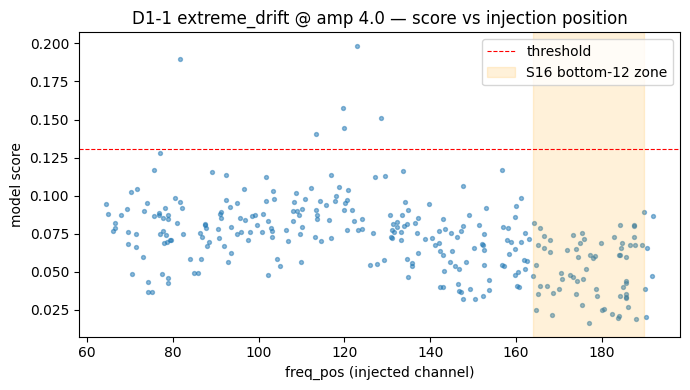

In [67]:
# ---- S19 item 2: D1-1 @ 4.0 score vs freq_pos ----
from scipy.stats import spearmanr
import matplotlib.pyplot as plt

d11 = scores[(scores.family == 'D1-1_extreme_drift') & (scores.amplitude == 4.0)] \
        .merge(man[['sample_id','freq_pos']], on='sample_id')
assert len(d11) == 300

rho, p = spearmanr(d11.freq_pos, d11.score)
print(f"Spearman rho = {rho:+.3f}, p = {p:.2e}, N = {len(d11)}")

plt.figure(figsize=(7,4))
plt.scatter(d11.freq_pos, d11.score, s=8, alpha=0.5)
plt.axhline(0.1309, color='r', ls='--', lw=0.8, label='threshold')
plt.axvspan(164, 190, color='orange', alpha=0.15, label='S16 bottom-12 zone')
plt.xlabel('freq_pos (injected channel)'); plt.ylabel('model score')
plt.title('D1-1 extreme_drift @ amp 4.0 — score vs injection position')
plt.legend(); plt.tight_layout()
plt.savefig('/kaggle/working/d11_score_vs_freqpos.png', dpi=120)
plt.show()

In [68]:
# ---- S19 item 2b: is the gradient general, and is it position or edge? ----
from scipy.stats import spearmanr
cells = [('D1-1_extreme_drift', a) for a in [0.25, 0.5, 1.0, 2.0, 4.0]] + \
        [('D1-2_quadratic', 4.0), ('D1-3_s_shaped', 4.0),
         ('D2-1_zero_drift', 4.0), ('D2-5_high_drift', 0.5)]
print(f"{'family':22s} {'amp':>5s} {'rho':>7s} {'p':>9s}")
for fam, amp in cells:
    g = scores[(scores.family == fam) & (scores.amplitude == amp)] \
          .merge(man[['sample_id','freq_pos']], on='sample_id')
    rho, p = spearmanr(g.freq_pos, g.score)
    print(f"{fam:22s} {amp:5.2f} {rho:+7.3f} {p:9.2e}")

family                   amp     rho         p
D1-1_extreme_drift      0.25  -0.191  9.00e-04
D1-1_extreme_drift      0.50  -0.148  1.05e-02
D1-1_extreme_drift      1.00  -0.393  1.63e-12
D1-1_extreme_drift      2.00  -0.359  1.43e-10
D1-1_extreme_drift      4.00  -0.484  5.43e-19
D1-2_quadratic          4.00  -0.179  1.81e-03
D1-3_s_shaped           4.00  +0.173  2.63e-03
D2-1_zero_drift         4.00  -0.068  2.38e-01
D2-5_high_drift         0.50  -0.173  2.67e-03


In [69]:
# ---- S19 item 4, Step A: fingerprint BEFORE surgery ----
import hashlib

r = man[man.sample_id == coh[coh.group == 'Q3_dispersed'].sample_id.iloc[0]].iloc[0]
print("fingerprint sample:", r.sample_id)

a1 = regenerate(r, base=SRC[r.source_id])
a2 = regenerate(r, base=SRC[r.source_id])
print("deterministic:", np.array_equal(a1, a2))

SHA_BEFORE = hashlib.sha256(a1.astype(np.float32).tobytes()).hexdigest()[:16]
print("SHA_BEFORE:", SHA_BEFORE)

# score it and compare against the saved Phase 3 value (exact recipe from S7)
import cv2, torch
x = np.vstack(a1[::2].astype(np.float32)).transpose((1, 0))   # (256, 819)
x = cv2.resize(x, (512, 512))
x = torch.from_numpy(x)[None, None, :, :].float().to(device)
with torch.no_grad():
    s_now = torch.sigmoid(model(x)).item()
s_saved = scores[scores.sample_id == r.sample_id].score.iloc[0]
print(f"score now {s_now:.6f} vs saved {s_saved:.6f}  diff {abs(s_now - s_saved):.2e}")

fingerprint sample: D1-5_dispersed_burst_amp4.0_0137
deterministic: True
SHA_BEFORE: 2b9a8c3936c9f30e
score now 0.031257 vs saved 0.031257  diff 2.26e-10
